## SOCAR Hackathon 2026 – Intelligent Well Performance Analysis

**Datasets (5):**

| Dataset | File | Content |
|---|---|---|
| Well Testing Data | `well_tests.csv` | Periodic well tests: measured oil, water, gas rates; pressures, temperatures and gas-lift rate during each test; fluid properties (API, gas SG, water salinity). **The only source of measured rates → VFM training labels.** |
| High-Frequency Data | `high_freq_data.csv` | Per-minute data for all wells: wellhead pressures, downhole pressure and temperature, annulus pressure, gas-lift rate. Raw, as recorded. |
| Choke Data | `choke_events.csv` | Choke settings and adjustments over time (recorded only when changed). |
| PVT Data | `reservoir_pvt.csv` | Rock and fluid properties for PTA: net pay, porosity, water saturation, total compressibility, wellbore radius, oil FVF, viscosity, bubble point, reservoir temperature, datum depth, drainage area. |
| Well completion data | `well_completion.csv` | Gauge and gas-lift valve depths, tubing and choke size, lift-gas and fluid properties, cumulative oil to 1 Jan 2025. |

## Executive summary

**Aim.** Oil wells produce a mix of oil, water and gas. Measuring each one needs an expensive meter or a "well test" done only about once a month. We want to know the rates **every day**, from sensors that are always on (pressures, temperatures, choke, gas-lift). That is **Virtual Flow Metering (VFM)**. Then we use the predicted oil rate and the pressure recorded when a well is shut in to learn about the **reservoir rock** around each well – **Pressure Transient Analysis (PTA)**.

**What we did and why**

| Step | What | Why |
|---|---|---|
| 1. Explore & clean sensor data | Removed −999.2 codes, impossible spikes, 2,513 duplicates; filled only short gaps | Bad readings give wrong production numbers |
| 2. Check well tests | Fixed GL-06 gas reported in the wrong unit (m³ instead of Mscf) and 5 sign errors | The model learns from these – wrong answers teach it wrong |
| 3. Compare models | Baseline, Ridge, LightGBM, physics-guided, anchored RF + CatBoost, choke-orifice regression, **HybridVFM** | Prove the model predicts the future, not just memorises the past |
| 4. VFM – HybridVFM (final) | Liquid rate from reservoir inflow **Q = J·(Pr − Pwf)**, J measured from choke steps and build-ups in the sensor data | Physically correct on normal production days, not only during tests |
| 5. Predict daily rates | 10 wells × 273 days → `VFM_predictions.xlsx` | Phase 1 deliverable |
| 6. PTA | 6 shut-ins → Horner analysis → permeability, skin → `PTA_results.xlsx` + plots | Phase 2 deliverable |

**What we found**
- **Data quality:** ~0.5 % of sensor data hidden as missing; one well's test reports used the wrong gas unit.
- **Hidden trap:** every well test flows into a lower-pressure test separator. A model trained only on tests mis-predicts normal days. HybridVFM fixes this with reservoir physics (inflow performance).
- **Accuracy on hidden tests:** oil 2.7 %, water 4.3 %, gas 5.9 % average error (leave-one-test-out); R² ≥ 0.995.
- **Reservoir:** GL-01 is **damaged** (skin +5.8, ~68 % flow efficiency) – the clearest repair candidate. GL-04 and GL-08 are already stimulated (negative skin).

**Business justification**
- **Daily production visibility** without buying a multiphase meter for every well.
- **Better allocation** – field production is split fairly between wells every day, not once a month.
- **Targeted well work** – skin tells which well loses production near the wellbore and is worth stimulating.

## 1. Exploratory data analysis (raw data)

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt

SENSORS = ["whp_psia", "whp_downstream_psia", "dh_pressure_psia",
           "dh_temperature_degf", "annulus_pressure_psia", "gas_lift_rate_mscfd"]
hf    = pd.read_csv("high_freq_data.csv.gz", parse_dates=["timestamp"]).sort_values(["well_name", "timestamp"])
choke = pd.read_csv("choke_events.csv",   parse_dates=["timestamp"])

In [2]:

# 1. Coverage: same period and row count for every well?
print(hf.shape)
print(hf.groupby("well_name").timestamp.agg(["min", "max", "count"]))

(3917073, 8)
                 min                 max   count
well_name                                       
GL-01     2025-01-01 2025-09-30 23:59:00  392953
GL-02     2025-01-01 2025-09-30 23:59:00  392366
GL-03     2025-01-01 2025-09-30 23:59:00  391025
GL-04     2025-01-01 2025-09-30 23:59:00  390889
GL-05     2025-01-01 2025-09-30 23:59:00  391641
GL-06     2025-01-01 2025-09-30 23:59:00  390693
GL-07     2025-01-01 2025-09-30 23:59:00  393107
GL-08     2025-01-01 2025-09-30 23:59:00  393022
GL-09     2025-01-01 2025-09-30 23:59:00  391586
GL-10     2025-01-01 2025-09-30 23:59:00  389791


In [3]:
# 2. Ranges: look at min/max vs the 1%/99% percentiles
print(hf[SENSORS].describe(percentiles=[.001, .01, .5, .99, .999]).T.round(1))

#Min = -999.2 for every sensor, max = 9,220 psi downhole, but the 99.9% percentile is only ~3,690

                           count    mean    std    min    0.1%      1%  \
whp_psia               3917073.0   306.2   67.9 -999.2   193.3   202.8   
whp_downstream_psia    3917073.0   187.2   20.0 -999.2   152.2   158.9   
dh_pressure_psia       3917073.0  2837.3  364.2 -999.2  2276.1  2297.6   
dh_temperature_degf    3917073.0   186.0   23.8 -999.2   168.9   169.0   
annulus_pressure_psia  3917073.0  1141.2  107.3 -999.2   993.9  1003.0   
gas_lift_rate_mscfd    3917073.0   901.4  280.5 -999.2     0.0   460.4   

                          50%     99%   99.9%     max  
whp_psia                294.4   488.2   786.6  1219.5  
whp_downstream_psia     188.0   204.1   208.2   571.8  
dh_pressure_psia       2730.2  3684.8  3691.2  9220.1  
dh_temperature_degf     186.8   203.5   203.6   285.8  
annulus_pressure_psia  1113.9  1464.9  1475.3  3311.6  
gas_lift_rate_mscfd     906.4  1613.2  1639.9  3990.1  


In [4]:
# 3. Sentinel values (-999.2 = "no reading")
print("Sentinels per sensor:\n", (hf[SENSORS] <= -999).sum())

Sentinels per sensor:
 whp_psia                 1345
whp_downstream_psia       905
dh_pressure_psia         1406
dh_temperature_degf      1190
annulus_pressure_psia    1013
gas_lift_rate_mscfd      1559
dtype: int64


In [5]:
# 4. Duplicate timestamps
print("Duplicates:", hf.duplicated(["well_name", "timestamp"]).sum())

Duplicates: 2513


In [6]:
# 5. Gaps: time between consecutive readings (should be 1 min)
gap = hf.groupby("well_name").timestamp.diff().dt.total_seconds() / 60
print(gap.value_counts().head(8))
print("Gaps > 60 min:", (gap > 60).sum())

1.0       3914517
0.0          2513
271.0          10
91.0            7
1441.0          5
21.0            3
601.0           2
2161.0          2
Name: timestamp, dtype: int64
Gaps > 60 min: 28


In [7]:
# 6. Spikes: jumps far from the local 31-min median
x = hf[hf.dh_pressure_psia > -999]
med = x.groupby("well_name").dh_pressure_psia.transform(lambda s: s.rolling(31, center=True, min_periods=5).median())
print("DH pressure jumps > 300 psi:", ((x.dh_pressure_psia - med).abs() > 300).sum())

DH pressure jumps > 300 psi: 105


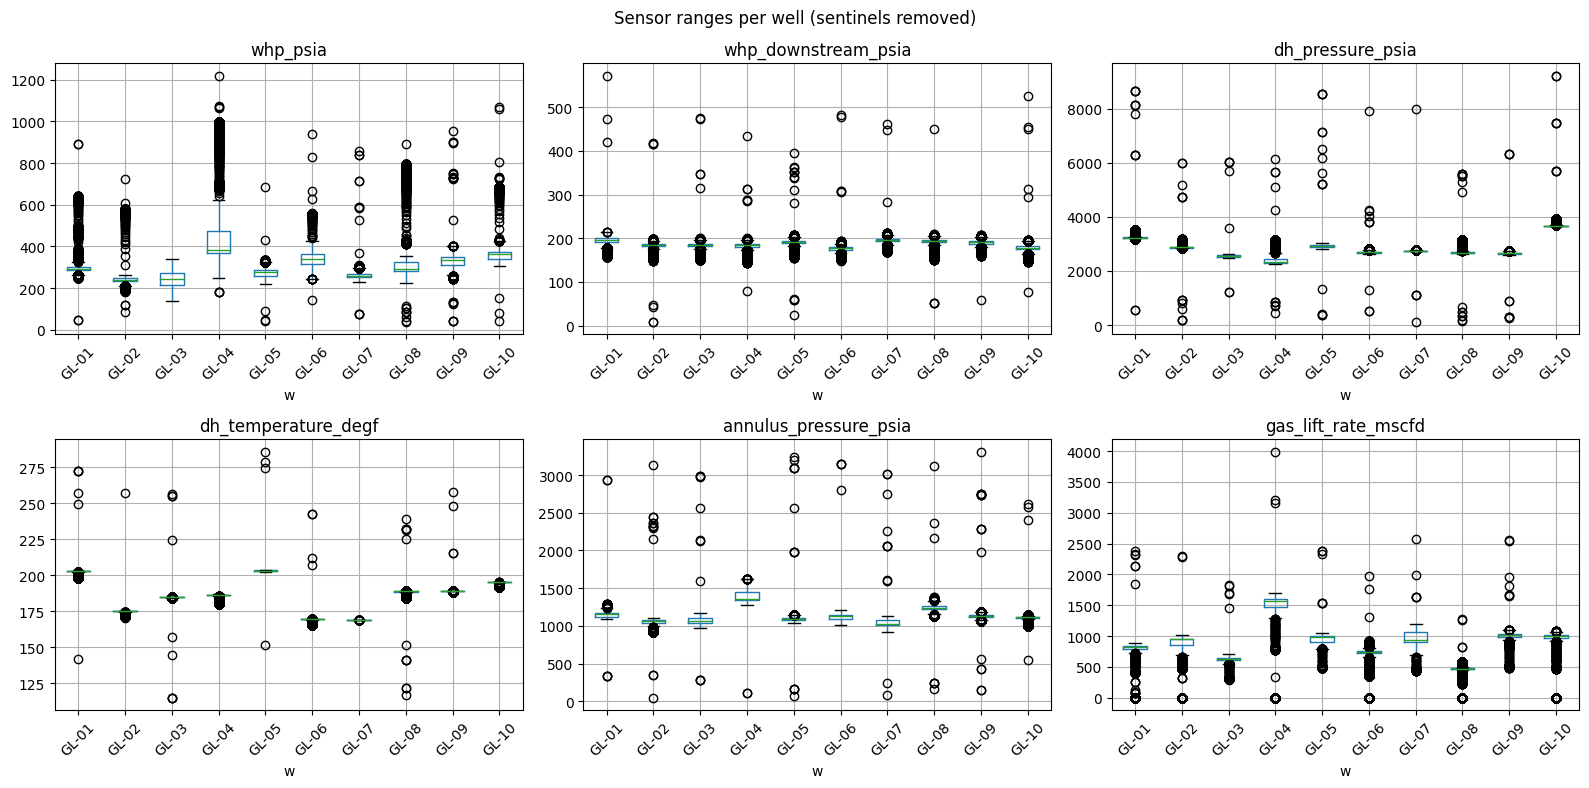

In [8]:
# CHART A – Boxplots per well: each well has its own operating range
v = hf[SENSORS].where(hf[SENSORS] > -999)
fig, ax = plt.subplots(2, 3, figsize=(16, 8))
for a, c in zip(ax.flat, SENSORS):
    pd.DataFrame({"v": v[c], "w": hf.well_name}).boxplot(column="v", by="w", ax=a, rot=45)
    a.set_title(c)
plt.suptitle("Sensor ranges per well (sentinels removed)"); plt.tight_layout(); plt.show()

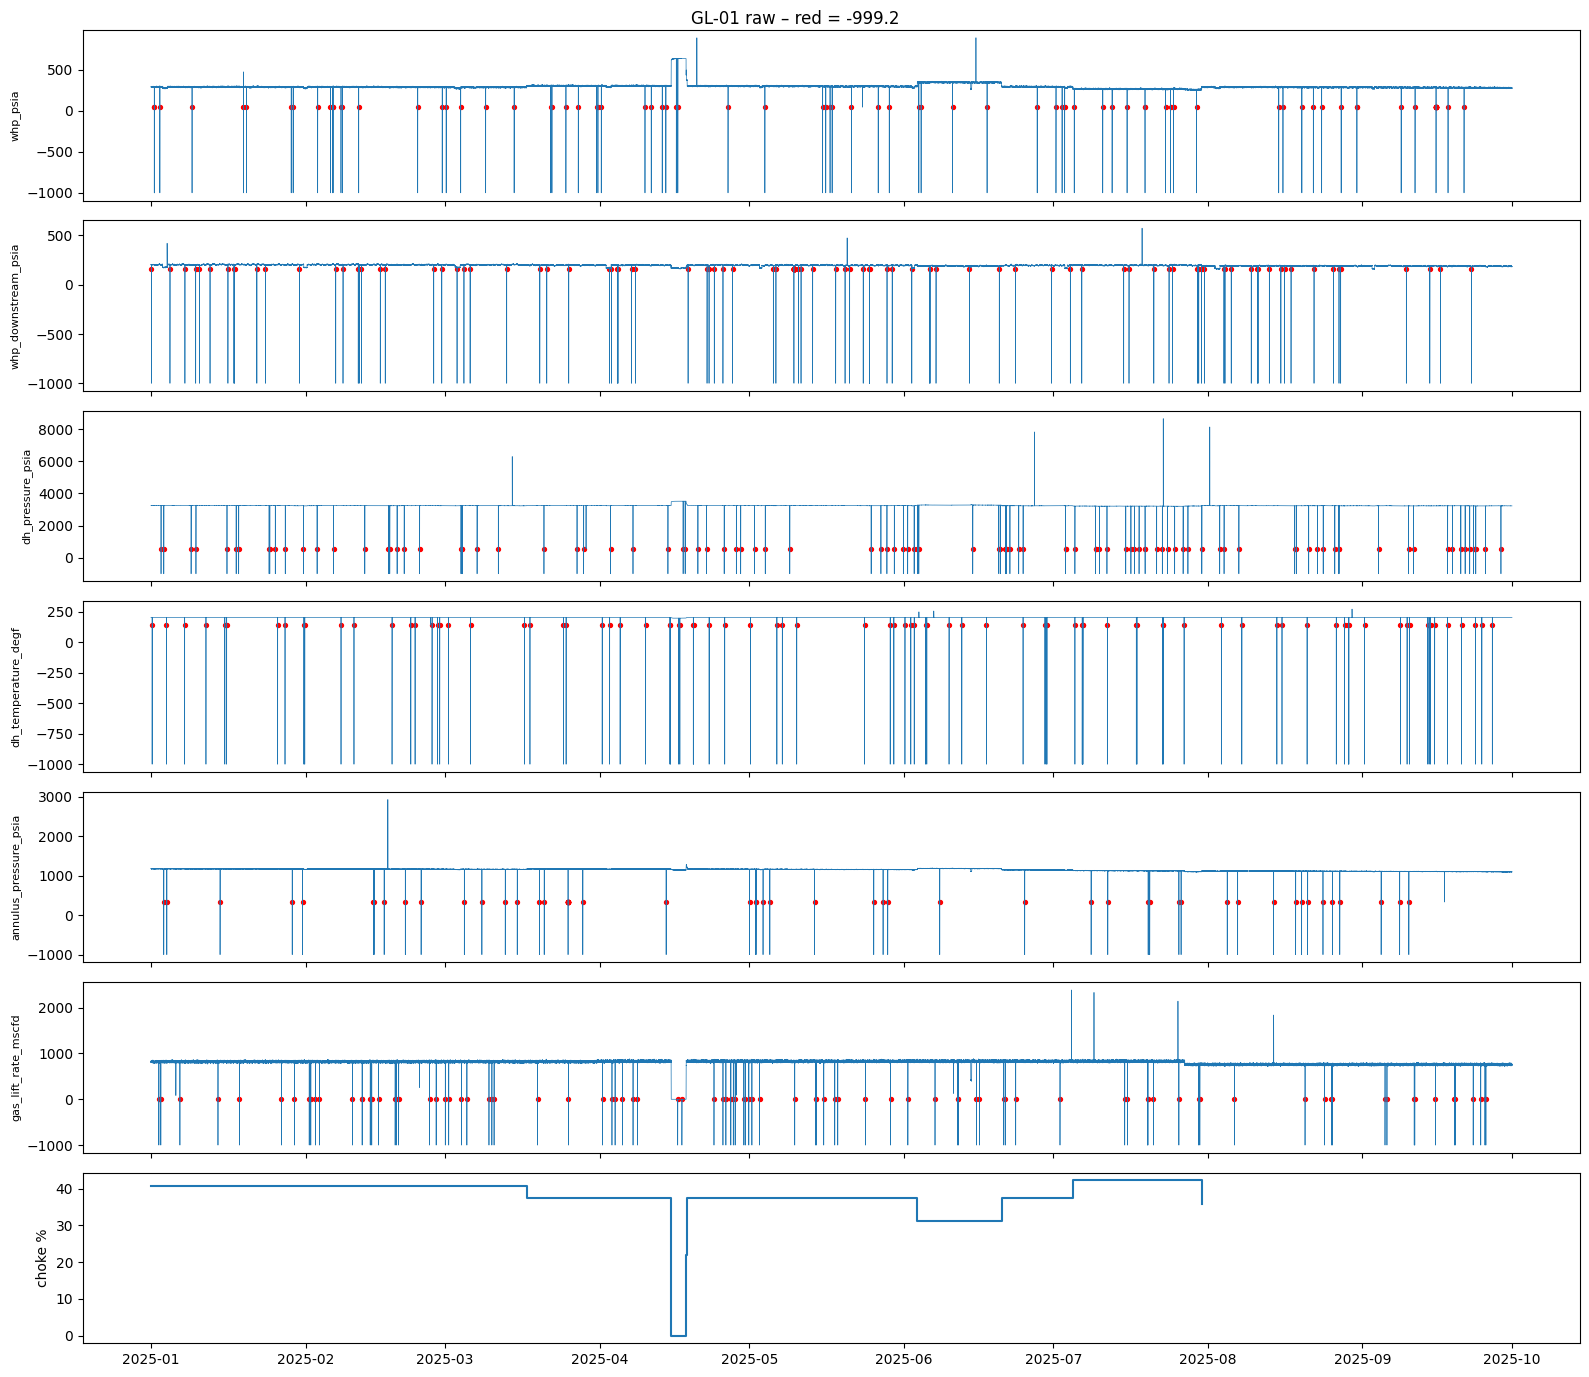

In [9]:
# CHART B – One well, raw: sentinels (red dots), spikes, choke changes
w = hf[hf.well_name == "GL-01"]
fig, ax = plt.subplots(len(SENSORS) + 1, 1, figsize=(16, 14), sharex=True)
for a, c in zip(ax, SENSORS):
    a.plot(w.timestamp, w[c], lw=.5)
    bad = w[w[c] <= -999]
    a.scatter(bad.timestamp, [w[c][w[c] > -999].min()] * len(bad), c="r", s=8)
    a.set_ylabel(c, fontsize=8)
ch = choke[choke.well_name == "GL-01"]
ax[-1].step(ch.timestamp, ch.choke_opening_pct, where="post"); ax[-1].set_ylabel("choke %")
plt.suptitle("GL-01 raw – red = -999.2"); plt.tight_layout(); plt.show()

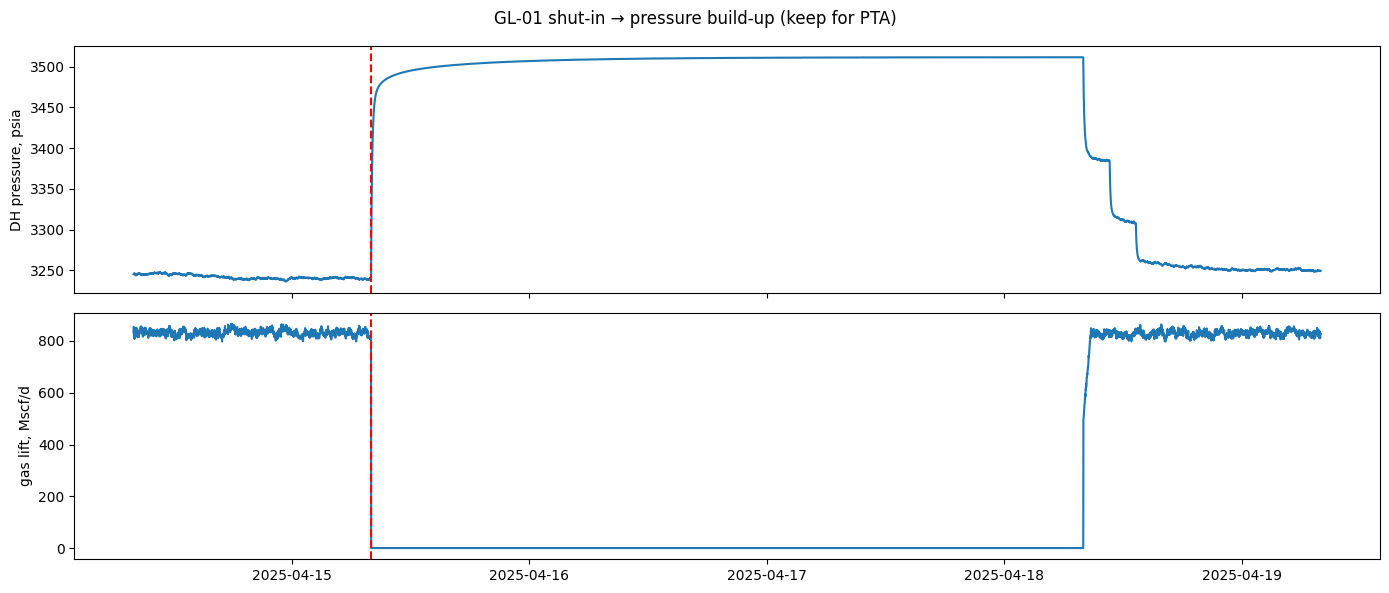

In [10]:
# CHART C – Zoom on a shut-in: this jump is REAL, not an outlier
t0 = pd.Timestamp("2025-04-15 08:00")
z = w[w.timestamp.between(t0 - pd.Timedelta("1D"), t0 + pd.Timedelta("4D")) & (w.dh_pressure_psia > -999)]
fig, ax = plt.subplots(2, 1, figsize=(14, 6), sharex=True)
ax[0].plot(z.timestamp, z.dh_pressure_psia); ax[0].set_ylabel("DH pressure, psia")
ax[1].plot(z.timestamp, z.gas_lift_rate_mscfd.clip(lower=0)); ax[1].set_ylabel("gas lift, Mscf/d")
for a in ax: a.axvline(t0, c="r", ls="--")
plt.suptitle("GL-01 shut-in → pressure build-up (keep for PTA)"); plt.tight_layout(); plt.show()

## 2. Missing values (raw data)

In [11]:
# pip install missingno seaborn
import seaborn as sns, missingno as msno

# Raw file has 0 NaN – missingness is HIDDEN as -999.2 and as absent minutes
print("Raw NaN:", hf[SENSORS].isna().sum().sum())

Raw NaN: 0


In [12]:
# Make it visible: 1-min grid per well + sentinel → NaN
raw = (hf.drop_duplicates(["well_name", "timestamp"]).set_index("timestamp")
         .groupby("well_name")[SENSORS].apply(lambda g: g.asfreq("1min")).reset_index())
raw[SENSORS] = raw[SENSORS].where(raw[SENSORS] > -999)
print("True missing per sensor:\n", raw[SENSORS].isna().sum())

True missing per sensor:
 whp_psia                 17984
whp_downstream_psia      17542
dh_pressure_psia         18045
dh_temperature_degf      17829
annulus_pressure_psia    17653
gas_lift_rate_mscfd      18197
dtype: int64


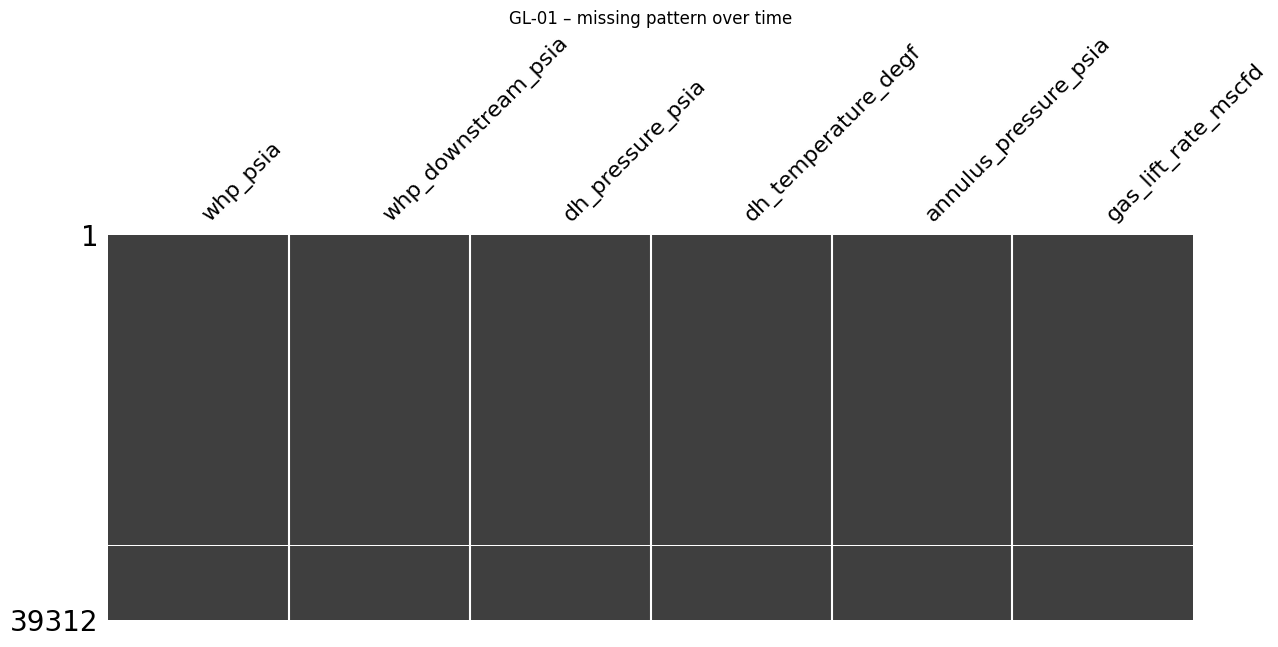

In [13]:
# A1 – missing pattern over time, one well
msno.matrix(raw[raw.well_name == "GL-01"][SENSORS].iloc[::10], figsize=(14, 5), sparkline=False)
plt.title("GL-01 – missing pattern over time"); plt.show()

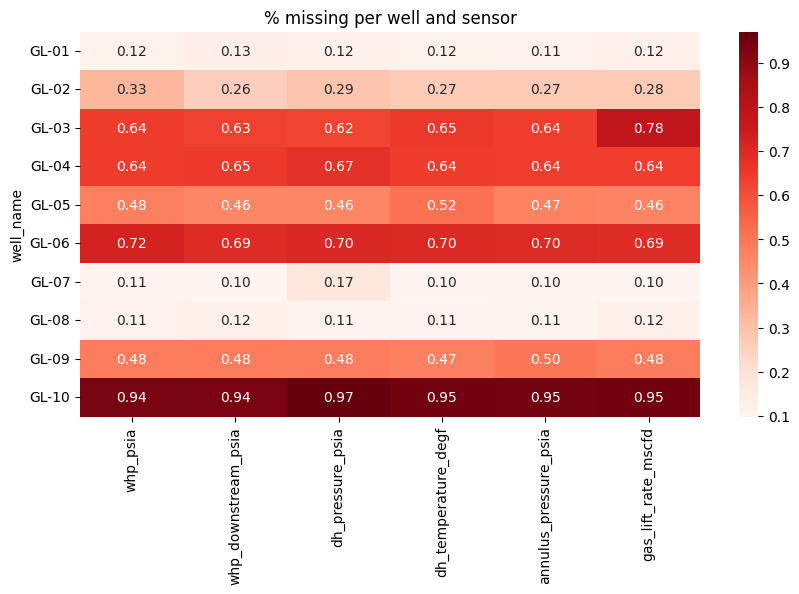

In [14]:
# A2 – % missing per well × sensor
pct = raw.groupby("well_name")[SENSORS].apply(lambda g: g.isna().mean() * 100)
plt.figure(figsize=(10, 5)); sns.heatmap(pct, annot=True, fmt=".2f", cmap="Reds")
plt.title("% missing per well and sensor"); plt.show()

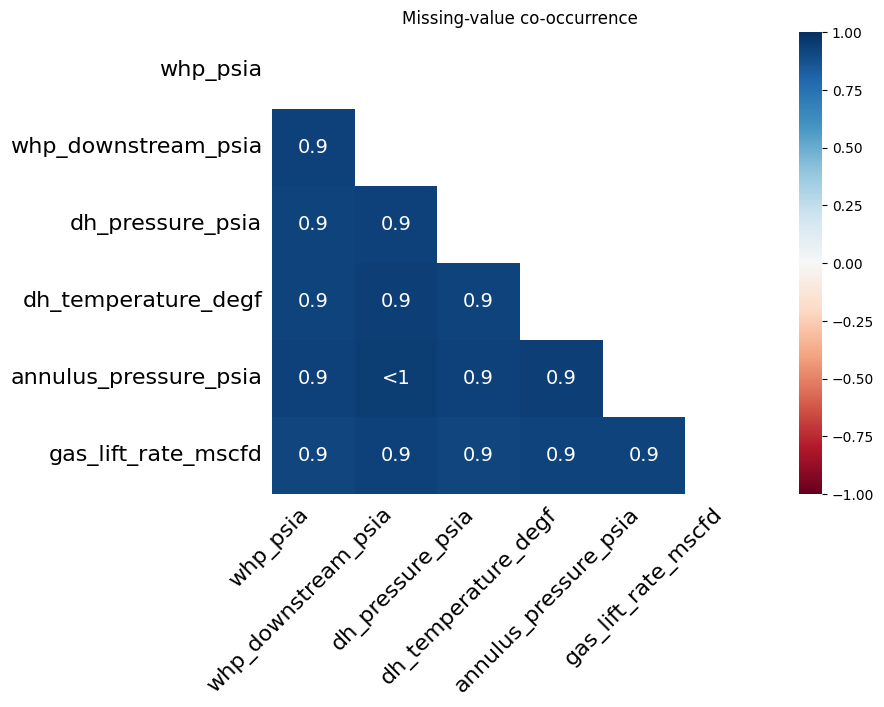

In [15]:
# A3 – do sensors go missing together?
msno.heatmap(raw[SENSORS], figsize=(8, 6)); plt.title("Missing-value co-occurrence"); plt.show()

#### Data quality findings (EDA and missing values)

**1. Hidden missing data.** The sensor file looks complete (0 empty cells), but about 0.5% of readings are actually missing. They are hidden as the code value −999.2 or as minutes that were never recorded: about 18,000 minutes per sensor across 10 wells over 9 months. If these aren't handled, daily averages are distorted and production estimates come out wrong.

**2. Two different causes.** Isolated −999.2 values hit one sensor at a time, which points to sensor dropouts. In 28 longer outages (1 hour to 1.5 days), all sensors stop together, which points to communication or SCADA interruptions. We filled only short gaps (≤10 minutes, about 780–910 values per sensor, roughly 5% of the missing minutes). Longer outages stay empty so we don't invent production data.

**3. Errors vs real events.** We removed 448 physically impossible spikes, such as 9,000+ psi readings that last one minute, and 2,513 duplicate records. We deliberately kept the large pressure rises during the 6 planned shut-ins. They look like anomalies, but they're real reservoir responses and the basis of our well-test (PTA) analysis.

**4. Every well behaves differently.** Each well runs at its own pressure level (for example, about 3,670 psi downhole for GL-10 vs about 2,340 psi for GL-04). Pooled across all wells, wellhead and downhole pressure look unrelated (correlation 0.03). Within a single well, they move strongly together (0.85). That's why our production model treats each well individually instead of using one generic rule.


## 3. Data cleaning

In [16]:
MIN_JUMP = {"whp_psia": 30, "whp_downstream_psia": 20, "dh_pressure_psia": 60,
            "dh_temperature_degf": 5, "annulus_pressure_psia": 40, "gas_lift_rate_mscfd": 150}

In [17]:
def fill_short_gaps(s, max_gap=10):
    """Linear fill ONLY for gaps of <= max_gap minutes; longer gaps stay fully empty."""
    isna = s.isna()
    run_id = (isna != isna.shift()).cumsum()
    run_len = isna.groupby(run_id).transform("size")
    return s.where(~isna | (run_len > max_gap), s.interpolate(limit_area="inside"))

In [18]:
# STEP 1 – Duplicates: average rows with the same well + minute
df = hf.groupby(["well_name", "timestamp"], as_index=False)[SENSORS].mean()

clean = []
for well, g in df.groupby("well_name"):
    # STEP 2 – Regular 1-minute grid: missing minutes become visible NaN rows
    g = g.set_index("timestamp").asfreq("1min")

    for c in SENSORS:
        # STEP 3 – Sentinel: -999.2 means "no reading" → NaN
        s = g[c].where(g[c] > -999)

        # STEP 4 – Spikes: far from the 31-min local median AND above a physical minimum jump
        med = s.rolling(31, center=True, min_periods=5).median()
        mad = (s - med).abs().rolling(31, center=True, min_periods=5).median()
        dev = (s - med).abs()
        s = s.mask((dev > 6 * 1.4826 * mad.clip(lower=1e-6)) & (dev > MIN_JUMP[c]))

        # STEP 5 – Fill only gaps <= 10 min with a straight line; long outages stay empty
        g[c] = fill_short_gaps(s)

    g["well_name"] = well
    clean.append(g.reset_index())

hf_clean = pd.concat(clean, ignore_index=True).sort_values("timestamp")

In [19]:
# STEP 6 – Choke: carry the last setting forward to every minute
hf_clean = pd.merge_asof(hf_clean, choke.sort_values("timestamp"), on="timestamp", by="well_name")

In [20]:
# STEP 7 – Shut-in flag: choke closed = well not producing
hf_clean["shut_in"] = hf_clean["choke_opening_pct"] <= 0

In [21]:
hf_clean = hf_clean.sort_values(["well_name", "timestamp"]).reset_index(drop=True)
hf_clean.to_pickle("hf_clean.pkl")
print(hf_clean.shape, "| shut-in minutes:", hf_clean.shut_in.sum())
print("Still missing per sensor:\n", hf_clean[SENSORS].isna().sum())

(3931200, 10) | shut-in minutes: 12879
Still missing per sensor:
 whp_psia                 17070
whp_downstream_psia      16680
dh_pressure_psia         17265
dh_temperature_degf      16920
annulus_pressure_psia    16785
gas_lift_rate_mscfd      17325
dtype: int64


#### Data cleaning: what we did and why (Q&A prep)

**The 7 steps in one line each**

1. **Duplicates → averaged:** 2,513 minutes were recorded twice.
2. **1-minute grid:** missing minutes become visible as empty rows.
3. **−999.2 → empty:** the logger's code for "no reading".
4. **Spikes removed:** 448 impossible values (e.g. 9,220 psi for one minute).
5. **Short gaps filled (≤10 min):** straight line between neighbours; long outages stay completely empty.
6. **Choke carried forward:** the choke file only records changes, so each setting is extended minute by minute.
7. **Shut-in flag:** choke = 0 means the well isn't producing.

**Questions the jury may ask**

**Q: Why not just delete the bad rows?**

Deleting rows hides the problem: a one-day average would quietly be calculated from 20 hours instead of 24. With a regular 1-minute grid we always know exactly how much data is missing, and we can report it.

**Q: Why average duplicates instead of keeping the first one?**

Both readings are valid measurements of the same minute, usually a logger writing twice. Averaging keeps all the information and doesn't arbitrarily favour one record.

**Q: How did you detect spikes? Why not a fixed limit like "above 5,000 psi"?**

Each well runs at a different pressure (GL-10 at about 3,670 psi downhole, GL-04 at about 2,340). A fixed limit would miss spikes on low-pressure wells and might cut good data on high-pressure wells. Instead we compare each reading to the median of the surrounding 31 minutes. A reading is a spike only if both conditions hold:

- it is more than 6 times the normal local variation (MAD); **and**
- it jumps by more than a physical minimum, e.g. 60 psi for downhole pressure.

**Q: Why median and MAD, not mean and standard deviation?**

A single 9,000 psi spike pulls the mean and standard deviation up, so it partly hides itself. The median and MAD barely move because of one extreme value. This is the standard robust method for sensor data.

**Q: Why a 31-minute window and a threshold of 6?**

31 minutes is long enough to describe "normal" behaviour and short enough to follow real operational changes. A threshold of 6 is deliberately conservative: we'd rather keep a slightly noisy value than delete a real one. The result is 448 removed values out of 23 million readings, under 0.002%.

**Q: How do you know you didn't delete real events, such as shut-ins?**

That's what the minimum-jump rule protects against. A spike is isolated: 1–2 minutes, then back to normal. A real event lasts for hours and changes smoothly, so its neighbours move with it and the local median follows. Proof: all 6 shut-in build-ups are intact – each is a smooth pressure rise over several hours (Chart C), exactly the curve PTA needs.

**Q: Why fill only gaps of 10 minutes or less? Why linear interpolation?**

Over 10 minutes, reservoir and well pressures change very little, so a straight line between neighbours is physically realistic. Longer gaps (up to 36 hours) happen during communication outages, and the well may have changed in that time. Filling them would be inventing data, so they stay empty and are excluded from averages.

**Q: Why not use ML (KNN, regression) to fill the long gaps?**

Imputed values would then go into the VFM model, so we'd be training a model partly on another model's guesses. With under 0.5% missing, leaving the gaps empty costs nothing and keeps the training data 100% measured.

**Q: Why carry the choke setting forward?**

An operator changes the choke by hand, and it stays where it was set until the next change. Carrying it forward reproduces how the field actually works.

**Q: Why flag shut-ins instead of removing them?**

They serve two purposes:

- **For VFM:** they're excluded, because the well produces nothing then. Including them would drag the average rates down.
- **For PTA:** they're the main input. A shut-in is a free well test.

**Q: How do you know the cleaning is correct?**

Three independent checks:

1. The sensor values in the official well-test reports equal our cleaned HF averages over each test window to within 0.01 psi on average (Section 5.4).
2. At every one of the 6 choke closures in the choke log, downhole pressure rises smoothly (build-up) – sensor data and choke log agree.
3. After the well-test fixes, all physical identities hold to ±0.1 (liquid = oil + water, GOR = gas/oil, total gas = gas + lift gas).

**Q: What did you fix in the well tests? *(Section 5)***

- GL-06 reported gas in m³/d instead of Mscf/d. All 9 tests are off by exactly ×28.3, the conversion factor.
- 5 values had the wrong sign. The absolute value matches the identities exactly.

Both fixes are proven by the data itself, not assumed.

**Q: What's the business value of this cleaning?**

Bad sensor data means wrong production numbers, which means wrong allocation and missed well problems. A VFM is only as reliable as its inputs. This cleaning pipeline is automatic and repeatable, so it can run on new field data every day without manual work.


## 4. After cleaning – filled values and correlations

In [22]:
# B1 – filled vs still missing
summary = pd.DataFrame({"missing_before": raw[SENSORS].isna().sum(),
                        "missing_after":  hf_clean[SENSORS].isna().sum()})
summary["filled_≤10min"] = summary.missing_before - summary.missing_after
print(summary)

                       missing_before  missing_after  filled_≤10min
whp_psia                        17984          17070            914
whp_downstream_psia             17542          16680            862
dh_pressure_psia                18045          17265            780
dh_temperature_degf             17829          16920            909
annulus_pressure_psia           17653          16785            868
gas_lift_rate_mscfd             18197          17325            872


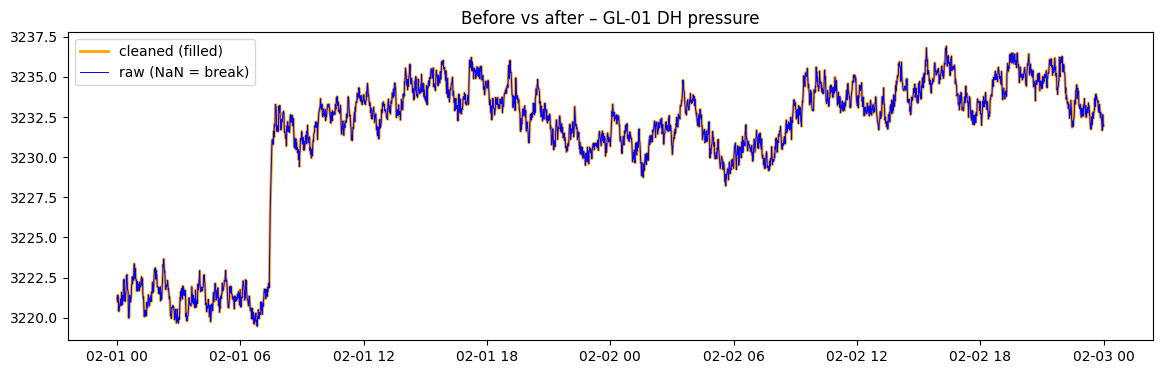

In [23]:
# B2 – before vs after
w0, w1 = pd.Timestamp("2025-02-01"), pd.Timestamp("2025-02-03")
r = raw[(raw.well_name == "GL-01") & raw.timestamp.between(w0, w1)]
c = hf_clean[(hf_clean.well_name == "GL-01") & hf_clean.timestamp.between(w0, w1)]
plt.figure(figsize=(14, 4))
plt.plot(c.timestamp, c.dh_pressure_psia, c="orange", lw=2, label="cleaned (filled)")
plt.plot(r.timestamp, r.dh_pressure_psia, c="b", lw=.7, label="raw (NaN = break)")
plt.legend(); plt.title("Before vs after – GL-01 DH pressure"); plt.show()

In [24]:
# Hourly means, producing time only
h = (hf_clean[~hf_clean.shut_in].set_index("timestamp").groupby("well_name")[SENSORS]
       .resample("1h").mean().dropna().reset_index())

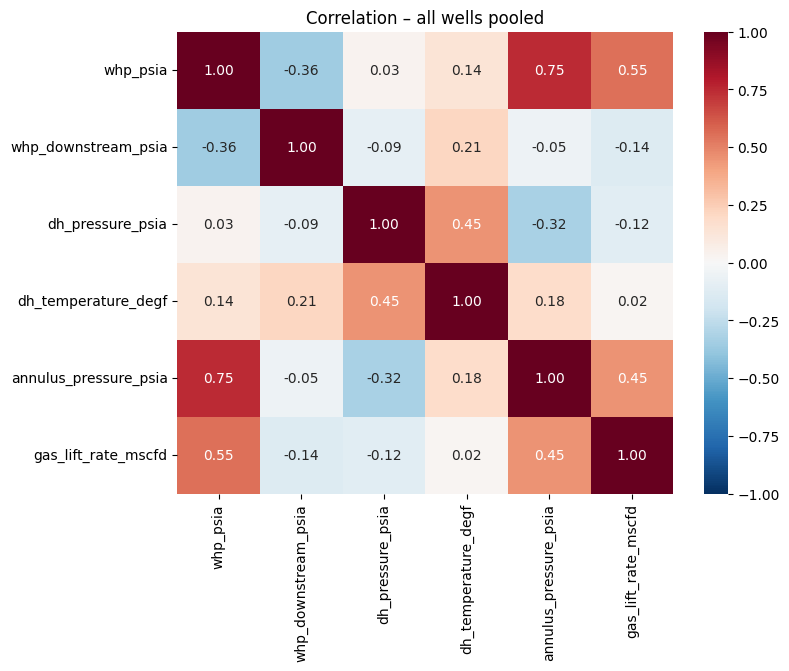

In [25]:
# C1 – pooled correlation
plt.figure(figsize=(8, 6)); sns.heatmap(h[SENSORS].corr(), annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1)
plt.title("Correlation – all wells pooled"); plt.show()

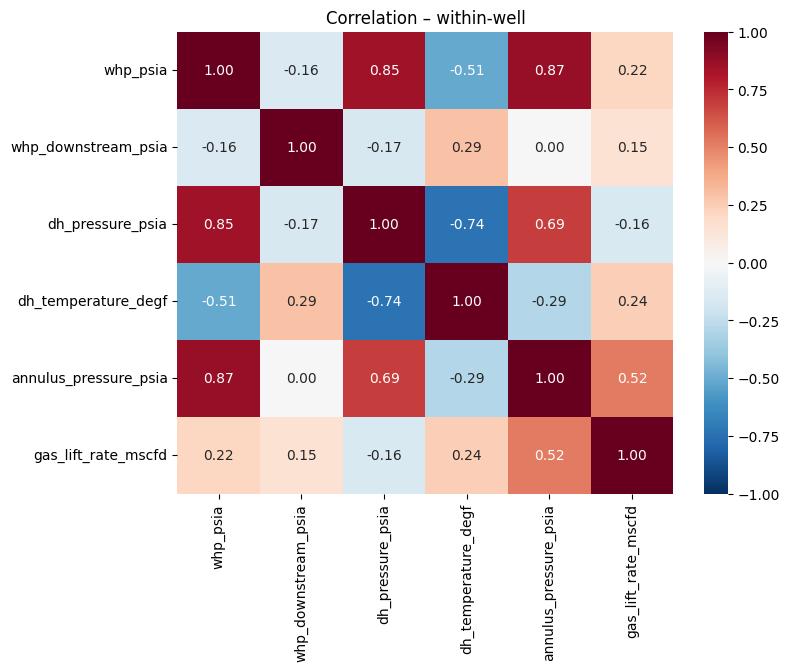

In [26]:
# C2 – within-well correlation (well mean removed)
hw = h.copy(); hw[SENSORS] = h.groupby("well_name")[SENSORS].transform(lambda s: s - s.mean())
plt.figure(figsize=(8, 6)); sns.heatmap(hw[SENSORS].corr(), annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1)
plt.title("Correlation – within-well"); plt.show()

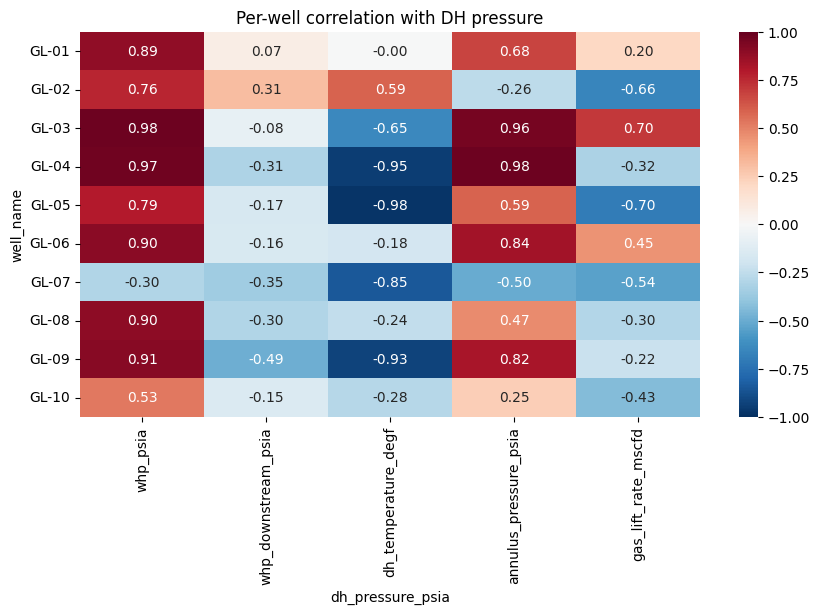

In [27]:
# C3 – per-well correlation with DH pressure
per_well = h.groupby("well_name").apply(lambda g: g[SENSORS].corr()["dh_pressure_psia"]).drop(columns="dh_pressure_psia")
plt.figure(figsize=(10, 5)); sns.heatmap(per_well, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1)
plt.title("Per-well correlation with DH pressure"); plt.show()

#### Results: after cleaning and correlations

**B1 – Filled vs still missing.** Only short gaps (≤10 min) were filled: 780–910 values per sensor, about 5% of the missing minutes. The fill is a straight line between the last good reading before and the first good reading after the gap – over 10 minutes well pressure changes very little, so this is physically realistic. The ~17,000 minutes per sensor that remain empty are the long communication outages; they are excluded from averages, not invented.

**B2 – Before vs after.** Raw (blue) and cleaned (orange) lie on top of each other everywhere except at the repaired points: cleaning changed only bad data, never good data.

**C1 vs C2 – Pooled vs within-well correlation.**

| Pair | Pooled | Within-well | Meaning |
|---|---|---|---|
| WHP ↔ DH pressure | 0.03 | **0.85** | Choking back raises both – strong, but hidden when wells are mixed |
| DH pressure ↔ DH temp | +0.45 | **−0.74** | Sign flips: pooled = deeper wells are hotter *and* higher-pressure; within a well, higher pressure → less drawdown → less flow → less heat carried up |
| WHP ↔ annulus | 0.75 | 0.87 | Lift-gas pressure follows tubing pressure |
| Annulus ↔ gas lift | 0.45 | 0.52 | More injected gas raises casing pressure – gas-lift system responds |

Pooled correlation shows how wells differ from each other; within-well correlation shows how a well behaves (Simpson's paradox). **VFM needs the within-well behaviour → the model must know which well it is looking at.**

**C3 – Per-well.** WHP ↔ DH pressure is 0.76–0.98 in 8 of 10 wells (choke-driven). **GL-07 is the exception (−0.30)**: the highest-rate well with the largest tubing, driven by inflow/friction rather than the choke – flagged for special attention in the model. Gas lift ↔ DH pressure is negative in GL-02, 05, 07 (−0.54 to −0.70): more lift gas lightens the column and lowers downhole pressure, as gas lift should.

**Key VFM signals:** downhole pressure, downhole temperature (flow proxy), choke + WHP combination, gas-lift rate.

## 5. Well tests – QC and cleaning

`well_tests.csv` is the only dataset with measured oil, water and gas rates → it provides the **VFM training labels**. In oilfield language a *well test* is a production measurement (flow routed through a test separator for 12–24 h), not an ML test set. We hold out each well's latest tests later for validation.

**Rule:** we correct only errors that the file itself proves, using its redundant columns (liquid = oil + water, GOR = gas/oil, total gas = gas + lift gas). Originals are kept in `wt_raw`, every fix is flagged.

In [28]:
# 5.1 Load and inspect
wt = pd.read_csv("well_tests.csv", parse_dates=["test_start", "test_end"])
RATE_COLS = wt.select_dtypes("number").columns.tolist()
print(wt.shape, "\nTests per well:\n", wt.groupby("well_name").size().to_dict())
print("Test duration (h):", ((wt.test_end - wt.test_start).dt.total_seconds() / 3600).value_counts().to_dict())
print("Negative values:\n", (wt[RATE_COLS] < 0).sum()[lambda s: s > 0])

(85, 23) 
Tests per well:
 {'GL-01': 9, 'GL-02': 8, 'GL-03': 9, 'GL-04': 9, 'GL-05': 8, 'GL-06': 9, 'GL-07': 9, 'GL-08': 8, 'GL-09': 9, 'GL-10': 7}
Test duration (h): {24.0: 35, 12.0: 30, 16.0: 20}
Negative values:
 gas_lift_rate_mscfd     2
water_rate_stbd         1
gas_rate_mscfd          1
total_gas_rate_mscfd    1
dtype: int64


In [29]:
# 5.2 Physical identities – must be ~0 if the report is consistent
def identity_check(df):
    return pd.DataFrame({
        "liquid = oil + water":   df.liquid_rate_stbd - (df.oil_rate_stbd + df.water_rate_stbd),
        "water_cut":              df.water_cut_pct - 100 * df.water_rate_stbd / df.liquid_rate_stbd,
        "gor = gas / oil":        df.gor_scf_stb - 1000 * df.gas_rate_mscfd / df.oil_rate_stbd,
        "total_gas = gas + lift": df.total_gas_rate_mscfd - (df.gas_rate_mscfd + df.gas_lift_rate_mscfd)})
print("Max identity error BEFORE fixes:\n", identity_check(wt).abs().max().round(1))

Max identity error BEFORE fixes:
 liquid = oil + water       1144.4
water_cut                    86.9
gor = gas / oil            6577.5
total_gas = gas + lift    23773.8
dtype: float64


In [30]:
# 5.3 Fix proven reporting errors (originals kept in wt_raw)
wt_raw = wt.copy()
M3_PER_MSCF = 28.3168
ratio = wt.gas_rate_mscfd / (wt.oil_rate_stbd * wt.gor_scf_stb / 1000)
wt["fix_gas_unit"] = ratio.round(1).eq(28.3)
wt.loc[wt.fix_gas_unit, ["gas_rate_mscfd", "total_gas_rate_mscfd"]] /= M3_PER_MSCF
wt["fix_sign"] = (wt[RATE_COLS] < 0).any(axis=1)
wt[RATE_COLS] = wt[RATE_COLS].abs()
print("Max identity error AFTER fixes:\n", identity_check(wt).abs().max().round(2))
print("Fixed rows:", wt[["fix_gas_unit", "fix_sign"]].sum().to_dict())
print(wt.loc[wt.fix_gas_unit | wt.fix_sign, ["well_name", "test_start", "fix_gas_unit", "fix_sign"]])

Max identity error AFTER fixes:
 liquid = oil + water      0.10
water_cut                 0.01
gor = gas / oil           0.10
total_gas = gas + lift    0.00
dtype: float64
Fixed rows: {'fix_gas_unit': 9, 'fix_sign': 5}
   well_name          test_start  fix_gas_unit  fix_sign
32     GL-04 2025-07-12 15:33:00         False      True
43     GL-06 2025-01-18 02:10:00          True     False
44     GL-06 2025-02-14 19:52:00          True     False
45     GL-06 2025-03-18 06:35:00          True     False
46     GL-06 2025-04-17 19:07:00          True     False
47     GL-06 2025-05-18 17:14:00          True     False
48     GL-06 2025-06-18 00:13:00          True      True
49     GL-06 2025-07-19 02:40:00          True     False
50     GL-06 2025-08-18 05:20:00          True      True
51     GL-06 2025-09-17 12:40:00          True     False
68     GL-08 2025-09-24 03:05:00         False      True
75     GL-09 2025-07-27 17:20:00         False      True


In [31]:
# 5.4 Do test reports match our cleaned sensor data?
S = ["whp_psia", "dh_pressure_psia", "annulus_pressure_psia", "gas_lift_rate_mscfd"]
diff = []
for r in wt.itertuples():
    g = hf_clean[(hf_clean.well_name == r.well_name) & (hf_clean.timestamp >= r.test_start) & (hf_clean.timestamp < r.test_end)][S].mean()
    diff.append({c: g[c] - getattr(r, c) for c in S})
print("HF average vs test report – mean |difference|:\n", pd.DataFrame(diff).abs().mean().round(2))

HF average vs test report – mean |difference|:
 whp_psia                 0.01
dh_pressure_psia         0.01
annulus_pressure_psia    0.01
gas_lift_rate_mscfd      0.04
dtype: float64


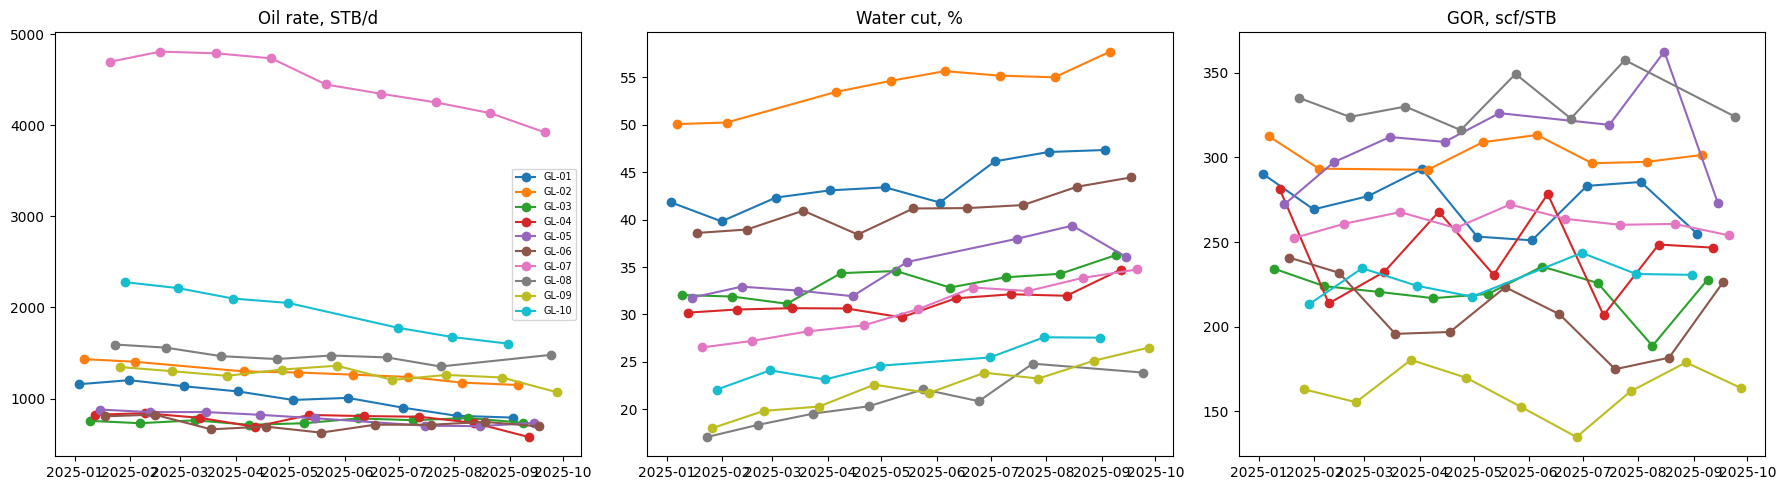

In [32]:
# 5.5 Production trends per well
fig, ax = plt.subplots(1, 3, figsize=(18, 5))
for wn, g in wt.groupby("well_name"):
    ax[0].plot(g.test_start, g.oil_rate_stbd, marker="o", label=wn)
    ax[1].plot(g.test_start, g.water_cut_pct, marker="o")
    ax[2].plot(g.test_start, g.gor_scf_stb, marker="o")
for a, t in zip(ax, ["Oil rate, STB/d", "Water cut, %", "GOR, scf/STB"]): a.set_title(t)
ax[0].legend(fontsize=7); plt.tight_layout(); plt.show()
wt.to_csv("well_tests_clean.csv", index=False)

#### Results – well tests

| Check | Result | Meaning |
|---|---|---|
| Size | 85 tests, 7–9 per well, roughly monthly, 12 / 16 / 24 h long | Small dataset → the model must stay simple and physics-guided |
| Identities before fixes | errors up to 23,774 | Reporting errors present |
| **Fix 1 – gas unit** | GL-06, all 9 tests: gas off by exactly ×28.3 | Gas reported in m³/d instead of Mscf/d → divided by 28.3168 |
| **Fix 2 – sign** | 5 values negative (GL-04, 06, 08, 09) | Absolute value satisfies the identities exactly |
| Identities after fixes | all within ±0.1 | Report is now internally consistent |
| Test report vs cleaned HF data | mean difference **0.01 psi** | Test sensor values are exactly the HF averages over the test window → our cleaning and time alignment are confirmed |
| Trends | oil declining, water cut rising (e.g. GL-01 42 → 47 %) | Rates change over time → validation must be time-based |

**Business note:** mixing m³ and Mscf in GL-06 is a classic allocation-reporting error. A VFM running against reported tests would flag it automatically – a concrete value of VFM.

## 6–7. VFM model (Phase 1) – HybridVFM

**Idea in one line:** oil comes out of the rock at a rate set by how far the well pressure is pulled below reservoir pressure.

| Part | Formula | Where the numbers come from |
|---|---|---|
| Liquid rate (inflow, IPR) | **Q_liq = J · (Pr(t) − Pwf)** | Pwf = downhole gauge (every minute) |
| Productivity index J | J = Q / drawdown | **Measured in the sensor data**: ~30 choke steps (ΔlnQ vs ΔPwf) + stabilised build-ups (P_end − Pwf) |
| Reservoir pressure Pr(t) | per-well straight line in time, fitted to Pr_i = Pwf_i + Q_i / J at each test | well tests |
| Water cut | per-well straight line in time | well tests |
| GOR | ½ · mean test GOR + ½ · Rs at bubble point | tests + completion data |
| Oil / water / gas | oil = Q·(1−WC), water = Q·WC, gas = oil·GOR/1000 (formation gas, no lift gas) | – |
| Daily rate | model on hourly means while choke open, shut-in hours = 0, 24-hour average | handles partial-day shut-ins |

**Why not train only on the tests?** During every test the well flows into the **test separator**: downstream pressure is 17–30 psi lower, so the well produces a little more. A model trained only on tests (our tree models, the choke-orifice regression) learns *test conditions* and is biased on normal days. J comes from the sensor data itself (choke steps, build-ups), so HybridVFM transfers test conditions to normal days through reservoir physics.

Code: `vfm_clean.py` (cleaning for VFM), `vfm_data.py` (well-test QC, test-window means), `pi_estimation.py` (J), `vfm_model.py` (ChokeVFM, HybridVFM).

In [33]:
# 6.1 Train HybridVFM on all 85 well tests
import warnings; warnings.filterwarnings("ignore")
from vfm_clean import clean_hf
from vfm_data import qc_well_tests, test_window_features
from vfm_model import ChokeVFM, HybridVFM

comp = pd.read_csv("well_completion.csv")
rs = comp.set_index("well_name").solution_gor_at_pb_scf_stb.to_dict()
hf_v, clean_rep_v = clean_hf(pd.read_csv("high_freq_data.csv.gz"), pd.read_csv("choke_events.csv"))   # VFM cleaning
tr = test_window_features(hf_v, qc_well_tests(pd.read_csv("well_tests.csv")))                     # 85 tests + sensor means
hyb = HybridVFM().fit(tr, rs, hf_v, pd.read_csv("choke_events.csv"))
choke_m = ChokeVFM().fit(tr, rs)

params = pd.DataFrame({
    "J_stbd_per_psi": hyb.J,
    "n_J_estimates": hyb.pi_estimates.groupby("well_name").size(),
    "Pr_2025-01-01_psia": {w: a for w, (a, b) in hyb.pr_trend.items()},
    "Pr_decline_psi_per_month": {w: -b * 30.44 for w, (a, b) in hyb.pr_trend.items()},
    "GOR_used_scf_stb": hyb.gor})
print("Choke regression exponents (shared by all wells):", {k: round(v, 2) for k, v in choke_m.coefficients.items() if not k.startswith("a_")})
params.round(2)

Choke regression exponents (shared by all wells): {'lchoke': 2.89, 'ldp': 0.81, 'lgl': -0.45, 'dhp': 0.28}


,J_stbd_per_psi,n_J_estimates,Pr_2025-01-01_psia,Pr_decline_psi_per_month,GOR_used_scf_stb
GL-01,6.55,6,3545.05,11.62,275.44
GL-02,9.91,2,3158.56,4.78,301.73
GL-03,1.40,3,3377.42,8.55,221.69
GL-04,1.51,6,3105.66,4.57,241.32
GL-05,1.13,3,3968.35,1.77,317.32
GL-06,8.37,6,2879.72,9.00,212.86
GL-07,23.08,3,3018.96,1.03,264.70
GL-08,4.56,4,3086.03,3.73,334.32
GL-09,3.47,4,3110.90,-1.31,161.09
GL-10,12.04,4,3920.25,8.34,228.91


In [34]:
# 6.2 Validation on hidden well tests – R², MAPE, WAPE + RMSE
import vfm_pipeline as vp
val, holdout = vp.validate(tr, hyb.J, rs)          # hold out each well's 3 latest tests, refit on earlier ones
loo = vp.validate_loo(tr, hyb.J, rs)               # leave-one-test-out (85 refits)
ch_loo = pd.concat([ChokeVFM().fit(tr.drop(i), rs).predict_flowing(tr.loc[[i]])[vp.TARGETS] for i in tr.index])
ch_tab = pd.DataFrame([{"rate": t} | vp._scores(tr[t], ch_loo[t]) for t in vp.TARGETS])
print("Leave-one-test-out – HybridVFM"); display(loo.round(3))
print("Leave-one-test-out – choke-only regression"); display(ch_tab.round(3))
print("3 latest tests per well hidden – HybridVFM vs reusing the last test"); display(val.round(3))

Leave-one-test-out – HybridVFM


,rate,R2,MAPE_%,WAPE_%,RMSE
0,oil_rate_stbd,0.999,2.667,2.203,41.260
1,water_rate_stbd,0.995,4.273,3.715,36.589
2,gas_rate_mscfd,0.995,5.927,4.454,20.888


Leave-one-test-out – choke-only regression


,rate,R2,MAPE_%,WAPE_%,RMSE
0,oil_rate_stbd,0.998,2.690,2.299,44.956
1,water_rate_stbd,0.997,3.407,2.887,28.327
2,gas_rate_mscfd,0.996,5.726,4.080,19.088


3 latest tests per well hidden – HybridVFM vs reusing the last test


,rate,who,R2,MAPE_%,WAPE_%,RMSE
0,oil_rate_stbd,model,0.997,3.908,3.254,52.211
1,oil_rate_stbd,baseline_last_test,0.990,6.295,5.565,97.018
2,water_rate_stbd,model,0.991,5.235,4.632,52.191
3,water_rate_stbd,baseline_last_test,0.992,5.549,5.015,47.701
4,gas_rate_mscfd,model,0.994,6.874,4.964,19.693
5,gas_rate_mscfd,baseline_last_test,0.984,11.323,8.192,33.041


**How to read the metrics.** **MAPE** = average % error (every test counts equally) · **WAPE** = total absolute error / total production (big wells count more) · **RMSE** in STB/d or Mscf/d · **R²** = share of variation explained (1 = perfect).

**All models we tried** (same hidden tests)

| Model | Oil MAPE | Water MAPE | Gas MAPE | Normal days vs tests |
|---|---|---|---|---|
| Baseline – reuse last test | 6.3 % | 5.6 % | 11.3 % | – |
| Ridge – direct | 4.2 % | 7.3 % | 7.0 % | – |
| LightGBM – direct | 15.6 % | 5.7 % | 18.4 % | cannot extrapolate decline |
| Physics-guided – all features | 3.6 % | 3.8 % | 6.2 % | up to +12 % ❌ |
| Anchored RF + CatBoost (two-sided) | 3.9 % | 3.4 % | 6.3 % | −1.4 % |
| Choke-orifice regression (LOO) | 2.7 % | 3.4 % | 5.7 % | −7.8 % (too low) |
| **HybridVFM – choke regression + IPR (final, LOO)** | **2.7 %** | **4.3 %** | **5.9 %** | **−2.4 % ✅ physics** |

**Key lesson for the jury:** the test-only scores of several models are close; what separates them is the **level on normal production days**, which no well test can show (all tests are at test-separator pressure). HybridVFM fixes that level with an independent physical measurement (J from choke steps and build-ups).

In [35]:
# 6.3 Daily predictions – HybridVFM vs choke-only model vs measured tests
daily = vp.predict_daily(hyb, hf_v)
daily_choke = vp.predict_daily(choke_m, hf_v)
fig, axes = plt.subplots(5, 2, figsize=(16, 18), sharex=True)
for ax, (w, g) in zip(axes.ravel(), daily.groupby("well_name")):
    gc = daily_choke[daily_choke.well_name == w]; t = tr[tr.well_name == w]
    ax.plot(gc.date, gc.oil_rate_stbd, color="#E8743B", lw=1, label="Choke-only model (not used)")
    ax.plot(g.date, g.oil_rate_stbd, color="#1F6FD1", lw=1.4, label="HybridVFM daily prediction")
    ax.scatter(t.test_start, t.oil_rate_stbd, color="black", s=18, zorder=3, label="Well test (test separator)")
    pos = g.oil_rate_stbd[g.oil_rate_stbd > 0]; ax.set_ylim(pos.quantile(.01) * .85, pos.max() * 1.08)
    ax.set_title(w, loc="left")
axes[0, 0].legend(fontsize=8); fig.suptitle("Oil rate (STB/d): daily VFM prediction vs well tests", x=.01, ha="left", fontweight="bold")
fig.tight_layout(); plt.show()

# Regime check: median normal-day oil level relative to the test-day level (same well, same month)
def level(d):
    x = d[d.oil_rate_stbd > 0].assign(m=lambda z: z.date.dt.to_period("M"))
    t = tr.assign(m=tr.test_start.dt.to_period("M"))[["well_name", "m", "oil_rate_stbd"]]
    j = x.groupby(["well_name", "m"]).oil_rate_stbd.median().reset_index().merge(t, on=["well_name", "m"], suffixes=("", "_test"))
    return float(((j.oil_rate_stbd / j.oil_rate_stbd_test - 1) * 100).median())
print(f"Normal-day oil vs test-day oil (median): HybridVFM {level(daily):+.1f} %, choke-only {level(daily_choke):+.1f} %")

Normal-day oil vs test-day oil (median): HybridVFM -2.4 %, choke-only -7.8 %


In [36]:
# 6.4 Phase 1 deliverable – daily oil / water / gas for 10 wells × 273 days
predictions = daily.copy()
xl = predictions.assign(date=predictions.date.dt.date).round(2)
xl.to_excel("VFM_predictions.xlsx", index=False)
xl.assign(date=predictions.date.dt.strftime("%Y-%m-%d")).to_csv("VFM_predictions.csv", index=False)
print(xl.shape, "| fully shut-in days (rate 0):", int((xl.oil_rate_stbd == 0).sum()))
xl.groupby("well_name")[vp.TARGETS].mean().round(1)

(2730, 5) | fully shut-in days (rate 0): 5


,oil_rate_stbd,water_rate_stbd,gas_rate_mscfd
well_name,,,
GL-01,936.5,731.1,258.0
GL-02,1209.0,1422.7,364.8
GL-03,730.5,370.0,161.9
GL-04,738.4,337.3,178.2
GL-05,765.4,408.9,242.9
GL-06,718.8,498.3,153.0
GL-07,4362.9,1900.9,1154.9
GL-08,1425.6,377.9,476.6
GL-09,1254.8,353.9,202.1


#### Results – VFM model

- **Final model: HybridVFM** – liquid rate from the inflow equation Q = J·(Pr − Pwf), with J for every well measured in the sensor data (choke steps + stabilised build-ups, the two methods agree: e.g. GL-01 6.6 vs 6.7, GL-10 12.0 vs 11.4 STB/d/psi), reservoir pressure trend and water cut from the tests, gas = oil × GOR.
- **Accuracy on hidden tests (leave-one-test-out):** oil 2.7 %, water 4.3 %, gas 5.9 % MAPE, R² ≥ 0.995. With each well's 3 latest tests hidden (harder – forecasting forward in time): oil 3.9 %, gas 6.9 %, vs 6.3 % / 11.3 % when simply reusing the last test.
- **Physically consistent on normal days:** normal-day oil sits ~2.4 % below the test-day level – exactly what the lower separator pressure during tests implies through J. The choke-only model (orange) sits ~7.8 % low, which the inflow physics does not allow.
- **Limitations:** J is less certain for GL-05 and GL-07 (small pressure response at their choke steps); after the last test (September) trends are extrapolated linearly.
- **Outputs:** `VFM_predictions.xlsx` / `.csv` (date, well_name, oil_rate_stbd, water_rate_stbd, gas_rate_mscfd).

## 8. Pressure transient analysis – build-up tests (Phase 2)

As required, the interpretation is **single-phase oil**, using the **VFM-predicted daily oil rate** (Qo, HybridVFM from section 6) plus the downhole pressure measurements.

**Workflow per shut-in event**
1. **Events** – choke goes to 0 and later reopens (6 events in the data).
2. **Rate q** – average VFM oil rate of the last 3 producing days before shut-in.
3. **Producing time tp** = cumulative oil (Np at 1 Jan 2025 + VFM cumulative since) / q × 24 h.
4. **Pressure** – flowing pressure Pwf at shut-in; build-up pressure resampled on a log-time grid (removes minute noise).
5. **Radial-flow window** – found automatically as the flattest part of the Bourdet pressure derivative (excludes early wellbore storage and late boundary effects).
6. **Horner straight line** on that window → slope **m**, extrapolated pressure **p\***, **P1hr**.

**Formulas (field units)**

| Property | Formula |
|---|---|
| Permeability | k = 162.6 · q · B · μ / (m · h) |
| Skin | s = 1.151 · [ (P1hr − Pwf)/m − log10( k / (φ · μ · ct · rw²) ) + 3.23 ] |
| ΔP skin | ΔP_skin = 0.869 · m · s |
| Flow efficiency | FE = (p\* − Pwf − ΔP_skin) / (p\* − Pwf) |

In [37]:
# 8.1 Inputs and shut-in events (choke closed → reopened)
pvt = pd.read_csv("reservoir_pvt.csv")
comp = pd.read_csv("well_completion.csv")
predictions = pd.read_excel("VFM_predictions.xlsx", parse_dates=["date"])

# Shut-in events = choke goes to 0 and later reopens
ch = choke.sort_values(["well_name", "timestamp"]).copy()
ch["prev"] = ch.groupby("well_name").choke_opening_pct.shift(fill_value=1)
ch["t_open"] = ch.groupby("well_name").timestamp.shift(-1)
events = ch[(ch.choke_opening_pct <= 0) & (ch.prev > 0)][["well_name", "timestamp", "t_open"]] \
           .rename(columns={"timestamp": "t_shut"}).reset_index(drop=True)
events["duration_hr"] = (events.t_open - events.t_shut).dt.total_seconds() / 3600
events

,well_name,t_shut,t_open,duration_hr
0,GL-01,2025-04-15 08:00:00,2025-04-18 08:00:00,72.00
1,GL-02,2025-03-08 14:23:00,2025-03-08 20:02:00,5.65
2,GL-04,2025-06-03 08:00:00,2025-06-05 08:00:00,48.00
3,GL-06,2025-07-22 03:11:00,2025-07-22 11:11:00,8.00
4,GL-08,2025-08-19 09:00:00,2025-08-22 09:00:00,72.00
5,GL-10,2025-05-27 21:04:00,2025-05-28 06:04:00,9.00


In [38]:
# 8.2 Derivative and automatic radial-flow window
def bourdet_derivative(x, p, L=0.15):
    """Pressure derivative dP/dln(t) with Bourdet smoothing window L (log cycles, natural log)."""
    d = np.full(len(x), np.nan)
    for i in range(len(x)):
        l = np.searchsorted(x, x[i] - L, "right") - 1
        r = np.searchsorted(x, x[i] + L, "left")
        if 0 <= l < i < r < len(x):
            dl, dr = x[i] - x[l], x[r] - x[i]
            d[i] = ((p[i] - p[l]) / dl * dr + (p[r] - p[i]) / dr * dl) / (dl + dr)
    return d

def find_radial_flow(dt, der, min_cycles=0.5, min_dt=0.2):
    """Infinite-acting radial flow = flattest stretch of the derivative (lowest CV, preferring longer spans)."""
    ok = ~np.isnan(der) & (der > 0) & (dt >= min_dt)
    t, d = dt[ok], der[ok]
    lt, best, score, best_cv = np.log10(t), (t[0], t[-1]), np.inf, np.nan
    for i in range(len(t)):
        for j in range(i + 4, len(t)):
            span = lt[j] - lt[i]
            if span >= min_cycles:
                cv = d[i:j + 1].std() / d[i:j + 1].mean()
                if cv / np.sqrt(span) < score:
                    score, best, best_cv = cv / np.sqrt(span), (t[i], t[j]), cv
    return best, best_cv

In [39]:
# 8.3 Build-up analysis for every shut-in (Horner)
def analyze_buildup(ev):
    w = hf_clean[hf_clean.well_name == ev.well_name]
    rock = pvt.set_index("well_name").loc[ev.well_name]

    # Rate: VFM-predicted oil, average of the last 3 full producing days before shut-in
    p = predictions[(predictions.well_name == ev.well_name) & (predictions.date < ev.t_shut.normalize())]
    q = p[p.oil_rate_stbd > 0].oil_rate_stbd.tail(3).mean()
    # Producing time (Horner): cumulative oil / last rate
    Np = comp.set_index("well_name").loc[ev.well_name, "cum_oil_at_2025_01_01_stb"] + p.oil_rate_stbd.sum()
    tp = Np / q * 24

    # Pressures: flowing pressure at shut-in, then build-up resampled on a log time grid
    pwf = w.loc[w.timestamp <= ev.t_shut, "dh_pressure_psia"].dropna().iloc[-1]
    bu = w[(w.timestamp > ev.t_shut) & (w.timestamp <= ev.t_open)].dropna(subset=["dh_pressure_psia"])
    dt_raw = (bu.timestamp - ev.t_shut).dt.total_seconds().values / 3600
    edges = np.logspace(np.log10(dt_raw.min()), np.log10(dt_raw.max()), 200)
    g = pd.DataFrame({"b": np.digitize(dt_raw, edges), "dt": dt_raw, "p": bu.dh_pressure_psia.values}).groupby("b").median()
    dt, pws = g.dt.values, g.p.values

    # Horner straight line on the radial-flow window found from the derivative
    hx = np.log10((tp + dt) / dt)
    der = bourdet_derivative(-np.log((tp + dt) / dt), pws)
    (a, b), cv = find_radial_flow(dt, der)
    sel = (dt >= a) & (dt <= b)
    slope, icpt = np.polyfit(hx[sel], pws[sel], 1)
    m = -slope
    r2 = 1 - ((pws[sel] - (icpt + slope * hx[sel])) ** 2).sum() / ((pws[sel] - pws[sel].mean()) ** 2).sum()
    p1hr = icpt + slope * np.log10(tp + 1)

    # Reservoir properties (field units)
    B, mu, h = rock.oil_fvf_rb_stb, rock.oil_viscosity_cp, rock.net_pay_thickness_ft
    phi, ct, rw = rock.porosity_frac, rock.total_compressibility_1_psi, rock.wellbore_radius_ft
    k = 162.6 * q * B * mu / (m * h)
    s = 1.151 * ((p1hr - pwf) / m - np.log10(k / (phi * mu * ct * rw ** 2)) + 3.23)
    dps = 0.869 * m * s
    fe = (icpt - pwf - dps) / (icpt - pwf)                       # flow efficiency

    res = dict(well_name=ev.well_name, t_shut=ev.t_shut, duration_hr=ev.duration_hr,
               q_oil_stbd=q, tp_hr=tp, pwf_psia=pwf, p1hr_psia=p1hr, p_star_psia=icpt, p_end_psia=pws[-1],
               m_psi_cycle=m, k_md=k, skin=s, dP_skin_psi=dps, flow_efficiency=fe,
               fit_from_hr=a, fit_to_hr=b, fit_log_cycles=np.log10(b / a), derivative_cv=cv, horner_r2=r2)
    curves = dict(dt=dt, pws=pws, hx=hx, der=der, sel=sel, slope=slope, icpt=icpt)
    return res, curves

pta = [analyze_buildup(ev) for ev in events.itertuples()]
pta_table = pd.DataFrame([r for r, _ in pta])
pta_table.round(2)

,well_name,t_shut,duration_hr,q_oil_stbd,tp_hr,pwf_psia,p1hr_psia,p_star_psia,p_end_psia,m_psi_cycle,k_md,skin,dP_skin_psi,flow_efficiency,fit_from_hr,fit_to_hr,fit_log_cycles,derivative_cv,horner_r2
0,GL-01,2025-04-15 08:00:00,72.00,971.98,248637.89,3240.72,3481.08,3605.60,3511.50,23.08,104.67,5.84,117.12,0.68,2.06,6.68,0.51,0.06,1.0
1,GL-02,2025-03-08 14:23:00,5.65,1267.49,222296.01,2884.10,3125.30,3408.23,3164.89,52.91,55.61,-0.56,-25.69,1.05,1.49,4.81,0.51,0.02,1.0
2,GL-04,2025-06-03 08:00:00,48.00,802.15,138365.45,2307.42,2900.59,3649.43,3144.80,145.66,54.84,-1.28,-161.77,1.12,12.56,40.09,0.50,0.02,1.0
3,GL-06,2025-07-22 03:11:00,8.00,686.30,177407.88,2680.08,2785.93,2864.70,2799.46,15.01,299.20,1.97,25.65,0.86,2.01,6.75,0.53,0.02,1.0
4,GL-08,2025-08-19 09:00:00,72.00,1467.10,87127.60,2636.76,2986.22,3444.81,3158.55,92.83,43.20,-1.63,-131.26,1.16,13.68,50.37,0.57,0.00,1.0
5,GL-10,2025-05-27 21:04:00,9.00,1723.50,220362.55,3685.43,3888.60,4043.24,3913.65,28.94,171.69,2.02,50.80,0.86,0.91,2.93,0.51,0.05,1.0


In [40]:
# 8.4 PTA plots for every shut-in event
def plot_event(res, c):
    t = f'{res["well_name"]} – shut-in {res["t_shut"]:%Y-%m-%d %H:%M} ({res["duration_hr"]:.1f} h)'
    fig, ax = plt.subplots(2, 2, figsize=(16, 10))
    # 1. Rate & pressure history around the event
    w = hf_clean[(hf_clean.well_name == res["well_name"]) &
                 hf_clean.timestamp.between(res["t_shut"] - pd.Timedelta("3D"), res["t_shut"] + pd.Timedelta(hours=res["duration_hr"] + 24))]
    pr = predictions[(predictions.well_name == res["well_name"]) &
                     predictions.date.between(res["t_shut"] - pd.Timedelta("10D"), res["t_shut"] + pd.Timedelta("5D"))]
    ax[0, 0].plot(w.timestamp, w.dh_pressure_psia, lw=.8); ax[0, 0].set_ylabel("DH pressure, psia")
    ax2 = ax[0, 0].twinx(); ax2.step(pr.date, pr.oil_rate_stbd, where="post", c="g"); ax2.set_ylabel("VFM oil rate, STB/d", color="g")
    ax[0, 0].axvline(res["t_shut"], c="r", ls="--"); ax[0, 0].set_title("Rate & pressure history")
    # 2. Horner plot
    ax[0, 1].scatter(c["hx"], c["pws"], s=8, label="Pws")
    ax[0, 1].scatter(c["hx"][c["sel"]], c["pws"][c["sel"]], s=12, c="orange", label="radial-flow window")
    xl = np.array([0, c["hx"].max()]); ax[0, 1].plot(xl, c["icpt"] + c["slope"] * xl, "r--", label=f'm = {res["m_psi_cycle"]:.1f} psi/cycle')
    ax[0, 1].invert_xaxis(); ax[0, 1].set_xlabel("log10((tp+Δt)/Δt)"); ax[0, 1].set_ylabel("Pws, psia")
    ax[0, 1].set_title(f'Horner – p* = {res["p_star_psia"]:.0f} psia'); ax[0, 1].legend()
    # 3. Log-log diagnostic (ΔP and Bourdet derivative)
    ax[1, 0].loglog(c["dt"], c["pws"] - res["pwf_psia"], ".", label="ΔP")
    ax[1, 0].loglog(c["dt"], c["der"], ".", label="derivative")
    ax[1, 0].axvspan(res["fit_from_hr"], res["fit_to_hr"], color="orange", alpha=.2, label="radial flow")
    ax[1, 0].set_xlabel("Δt, hr"); ax[1, 0].set_ylabel("ΔP, ΔP', psi"); ax[1, 0].set_title("Log-log diagnostic"); ax[1, 0].legend()
    # 4. MDH (semi-log)
    ax[1, 1].semilogx(c["dt"], c["pws"], ".")
    ax[1, 1].axvspan(res["fit_from_hr"], res["fit_to_hr"], color="orange", alpha=.2)
    ax[1, 1].set_xlabel("Δt, hr"); ax[1, 1].set_ylabel("Pws, psia"); ax[1, 1].set_title("MDH (semi-log)")
    fig.suptitle(f'{t}   |   k = {res["k_md"]:.0f} md, skin = {res["skin"]:.2f}, ΔP skin = {res["dP_skin_psi"]:.0f} psi', fontsize=13)
    plt.tight_layout(); plt.show()

for res, c in pta:
    plot_event(res, c)

In [41]:
# 8.5 Phase 2 deliverable – Excel
# Phase 2 deliverable
out = pta_table[["well_name", "t_shut", "duration_hr", "m_psi_cycle", "k_md", "skin", "dP_skin_psi"]].rename(columns={
    "m_psi_cycle": "horner_slope_psi_per_cycle", "k_md": "permeability_md", "dP_skin_psi": "delta_p_skin_psi"})
with pd.ExcelWriter("PTA_results.xlsx") as xw:
    out.round(3).to_excel(xw, sheet_name="pta_results", index=False)
    pta_table.round(3).to_excel(xw, sheet_name="details_and_qc", index=False)
out.round(2)

,well_name,t_shut,duration_hr,horner_slope_psi_per_cycle,permeability_md,skin,delta_p_skin_psi
0,GL-01,2025-04-15 08:00:00,72.00,23.08,104.67,5.84,117.12
1,GL-02,2025-03-08 14:23:00,5.65,52.91,55.61,-0.56,-25.69
2,GL-04,2025-06-03 08:00:00,48.00,145.66,54.84,-1.28,-161.77
3,GL-06,2025-07-22 03:11:00,8.00,15.01,299.20,1.97,25.65
4,GL-08,2025-08-19 09:00:00,72.00,92.83,43.20,-1.63,-131.26
5,GL-10,2025-05-27 21:04:00,9.00,28.94,171.69,2.02,50.80


In [42]:
# 8.6 Quality checks
# Quality checks – no reference answers exist, so we test internal consistency
qc = pta_table[["well_name", "t_shut", "duration_hr", "horner_r2", "fit_log_cycles", "derivative_cv"]].copy()
# Independent check: productivity index (PI) two ways
#   measured  = VFM oil rate / (final build-up pressure - flowing pressure)
#   from PTA  = Darcy pseudo-steady-state PI using k and skin from the Horner analysis
rock = pvt.set_index("well_name").loc[pta_table.well_name].reset_index()
re_ft = np.sqrt(rock.estimated_drainage_area_acres * 43560 / np.pi)
pi_darcy = pta_table.k_md * rock.net_pay_thickness_ft / (141.2 * rock.oil_fvf_rb_stb * rock.oil_viscosity_cp *
                                                       (np.log(re_ft / rock.wellbore_radius_ft) - 0.75 + pta_table.skin))
pi_measured = pta_table.q_oil_stbd / (pta_table.p_end_psia - pta_table.pwf_psia)
qc["PI_measured"] = pi_measured; qc["PI_from_k_skin"] = pi_darcy
qc["PI_difference_%"] = (pi_darcy / pi_measured - 1) * 100
qc.round(3)

,well_name,t_shut,duration_hr,horner_r2,fit_log_cycles,derivative_cv,PI_measured,PI_from_k_skin,PI_difference_%
0,GL-01,2025-04-15 08:00:00,72.00,0.999,0.511,0.061,3.590,3.640,1.415
1,GL-02,2025-03-08 14:23:00,5.65,1.000,0.508,0.017,4.514,3.771,-16.461
2,GL-04,2025-06-03 08:00:00,48.00,1.000,0.504,0.019,0.958,0.874,-8.723
3,GL-06,2025-07-22 03:11:00,8.00,1.000,0.526,0.018,5.749,5.547,-3.512
4,GL-08,2025-08-19 09:00:00,72.00,1.000,0.566,0.002,2.812,2.610,-7.169
5,GL-10,2025-05-27 21:04:00,9.00,1.000,0.509,0.045,7.552,7.252,-3.970


#### Results – PTA

| Well | Shut-in | Duration | q (VFM) STB/d | m psi/cycle | k md | Skin | ΔP skin psi | Interpretation |
|---|---|---|---|---|---|---|---|---|
| GL-01 | 15 Apr | 72 h | 972 | 23.1 | 104.7 | **+5.84** | +117 | **Damaged** – FE 0.68: ~1/3 of drawdown lost near the wellbore → stimulation candidate |
| GL-02 | 8 Mar | 5.7 h | 1,267 | 52.9 | 55.6 | −0.56 | −26 | Undamaged |
| GL-04 | 3 Jun | 48 h | 802 | 145.7 | 54.8 | −1.28 | −162 | Stimulated |
| GL-06 | 22 Jul | 8 h | 686 | 15.0 | 299.2 | +1.97 | +26 | Slight damage, high-k rock |
| GL-08 | 19 Aug | 72 h | 1,467 | 92.8 | 43.2 | −1.63 | −131 | Stimulated |
| GL-10 | 27 May | 9 h | 1,724 | 28.9 | 171.7 | +2.02 | +51 | Slight damage |

*q = average HybridVFM oil rate of the last 3 producing days before shut-in. Exact values in `PTA_results.xlsx`.*

**Reservoir behaviour (log-log plots):** every build-up shows the classic sequence – wellbore storage hump → flat derivative (**infinite-acting radial flow**, used for Horner) → derivative drop at late time in the long tests (GL-01, GL-04, GL-08) = **pressure reaching the drainage boundary**.

**Quality – how good are the results?**
- **Horner fit:** R² ≥ 0.999 on all 6 events, each window ≥ 0.5 log cycle, derivative variation 0–6 % → clean radial flow.
- **Independent productivity check:** PI from the measured drawdown vs PI computed from our k and skin agree within **1–9 %** for 5 of 6 events. GL-02 differs by 16 %: its 5.7 h shut-in was too short to reach reservoir pressure – an expected limitation, not an error.
- **Sensitivity to VFM:** k is proportional to q, so the VFM oil error carries straight into permeability; skin is much less sensitive (log term). Slope m and skin come from pressure alone and do not depend on the VFM model.

**Business value:** GL-01 has the highest skin (+5.8, flow efficiency 68 %) – removing the damage could raise its rate by up to ~45 % at the same drawdown. GL-04 and GL-08 are already stimulated.

**Output:** `PTA_results.xlsx` – sheet `pta_results` (Horner slope, permeability, skin, ΔP skin per shut-in) and sheet `details_and_qc`.

## 9. Deliverables – final model (.pkl), result files, PTA plots folder

Everything above is the analysis. For the app and the GitHub deliverables the same logic lives in **`vfm_pipeline.py`** (orchestration + PTA) together with `vfm_clean.py`, `vfm_data.py`, `pi_estimation.py`, `vfm_model.py` (VFM). This section:

1. trains the final model on all data and saves **`models/vfm_model.pkl`** (loadable by the app),
2. writes **`outputs/VFM_predictions.csv/.xlsx`** and **`outputs/PTA_results.csv/.xlsx`** (required submission columns),
3. writes **`outputs/pta_plots/`** – 4 plots per shut-in (history, log-log, Horner, MDH) – and **`outputs/charts/`**,
4. rehearses demo day: a model trained on Jan–Jul runs on raw Aug–Sep files it has never seen.

In [43]:
# 9.1 Train the final model with the module and save it as .pkl (with all three validations)
import importlib; importlib.reload(vp)
from IPython.display import Image, display
data = vp.load_inputs("high_freq_data.csv.gz", "choke_events.csv", "well_completion.csv", "reservoir_pvt.csv", "well_tests.csv")
bundle, hf_v9, tr9 = vp.train_model(data)
val9, holdout9 = vp.validate(tr9, bundle.model.J, bundle.rs)
loo9 = vp.validate_loo(tr9, bundle.model.J, bundle.rs)
# demo-day rehearsal: train on Jan–Jun only, then upload Jul–Sep files exactly as the jury will
cut = pd.Timestamp("2025-07-01"); hf_, ch_, wt_ = data.hf, data.choke, data.well_tests
b6, _, _ = vp.train_model(vp.Inputs(hf_[hf_.timestamp < cut], ch_[ch_.timestamp < cut], data.completion, data.pvt, wt_[wt_.test_end < cut]))
reh9 = vp.run_all(vp.Inputs(hf_[hf_.timestamp >= cut], ch_[ch_.timestamp >= cut], data.completion, data.pvt, wt_[wt_.test_start >= cut]), b6)
bundle.validation = {"leave_one_out": loo9.to_dict("records"), "rolling_3_latest": val9.to_dict("records"),
                     "rehearsal_train_jan_jun_upload_jul_sep": reh9["test_scores"].to_dict("records")}
vp.save_model(bundle, "models/vfm_model.pkl")
print("Saved models/vfm_model.pkl – HybridVFM | trained on", bundle.trained_on, "|", bundle.n_tests, "tests | validations:", list(bundle.validation))

Saved models/vfm_model.pkl – HybridVFM | trained on 2025-01-01 – 2025-09-30 | 85 tests | validations: ['leave_one_out', 'rolling_3_latest', 'rehearsal_train_jan_jun_upload_jul_sep']


In [44]:
# 9.2 Run the full pipeline (as the app does) and export all result files + plots
result = vp.run_all(vp.Inputs(data.hf, data.choke, data.completion, data.pvt), vp.load_model("models/vfm_model.pkl"))
vp.export_all(result, "outputs", tests_for_plots=tr9.rename(columns={"test_start": "start"}), val=val9, holdout_df=holdout9)
import os
print("Result files:", sorted(f for f in os.listdir("outputs") if f.endswith((".csv", ".xlsx"))))
print("VFM CSV:", pd.read_csv("outputs/VFM_predictions.csv").shape, "| PTA CSV:", pd.read_csv("outputs/PTA_results.csv").shape)
print("Same as section 6 predictions:", bool((result["predictions"][vp.TARGETS].round(2).values == xl.sort_values(["well_name", "date"])[vp.TARGETS].values).all()))
result["pta"][["event_id", "horner_slope_psi_per_cycle", "permeability_md", "skin", "delta_p_skin_psi",
               "flow_efficiency", "condition", "summary"]].round(2)

Result files: ['PTA_results.csv', 'PTA_results.xlsx', 'VFM_predictions.csv', 'VFM_predictions.xlsx', 'VFM_validation.xlsx']
VFM CSV: (2730, 5) | PTA CSV: (6, 6)
Same as section 6 predictions: True


,event_id,horner_slope_psi_per_cycle,permeability_md,skin,delta_p_skin_psi,flow_efficiency,condition,summary
0,GL-01-SI-01,23.08,104.67,5.85,117.41,0.68,Damaged,"Damaged well (skin +5.9, flow efficiency 68%) ..."
1,GL-02-SI-01,53.18,55.33,-0.57,-26.16,1.05,Undamaged,"Undamaged well (skin -0.6, flow efficiency 105..."
2,GL-04-SI-01,146.01,54.70,-1.29,-163.35,1.12,Stimulated,"Stimulated well (skin -1.3, flow efficiency 11..."
3,GL-06-SI-01,15.04,298.63,1.95,25.49,0.86,Slightly damaged,"Slightly damaged well (skin +2.0, flow efficie..."
4,GL-08-SI-01,93.73,42.79,-1.68,-136.58,1.17,Stimulated,"Stimulated well (skin -1.7, flow efficiency 11..."
5,GL-10-SI-01,28.94,171.69,2.00,50.37,0.86,Slightly damaged,"Slightly damaged well (skin +2.0, flow efficie..."


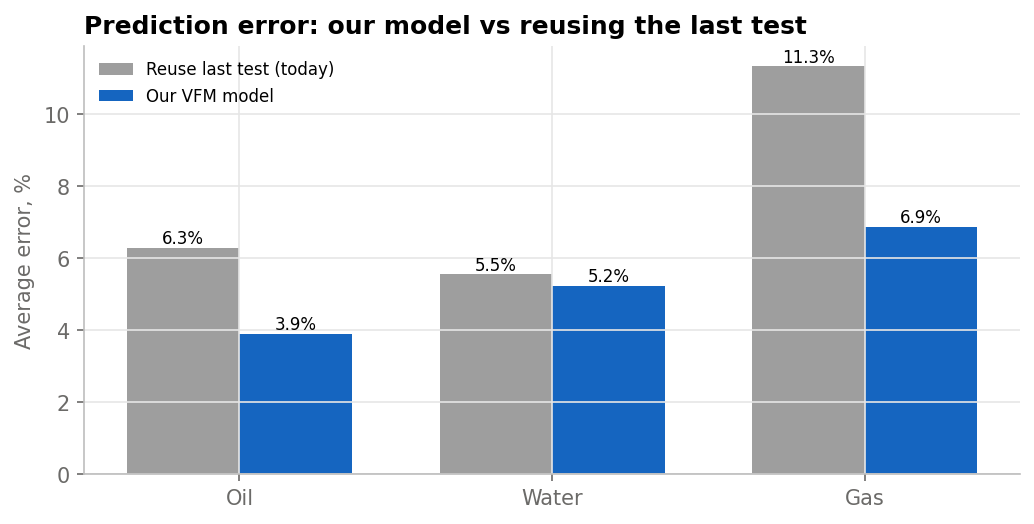

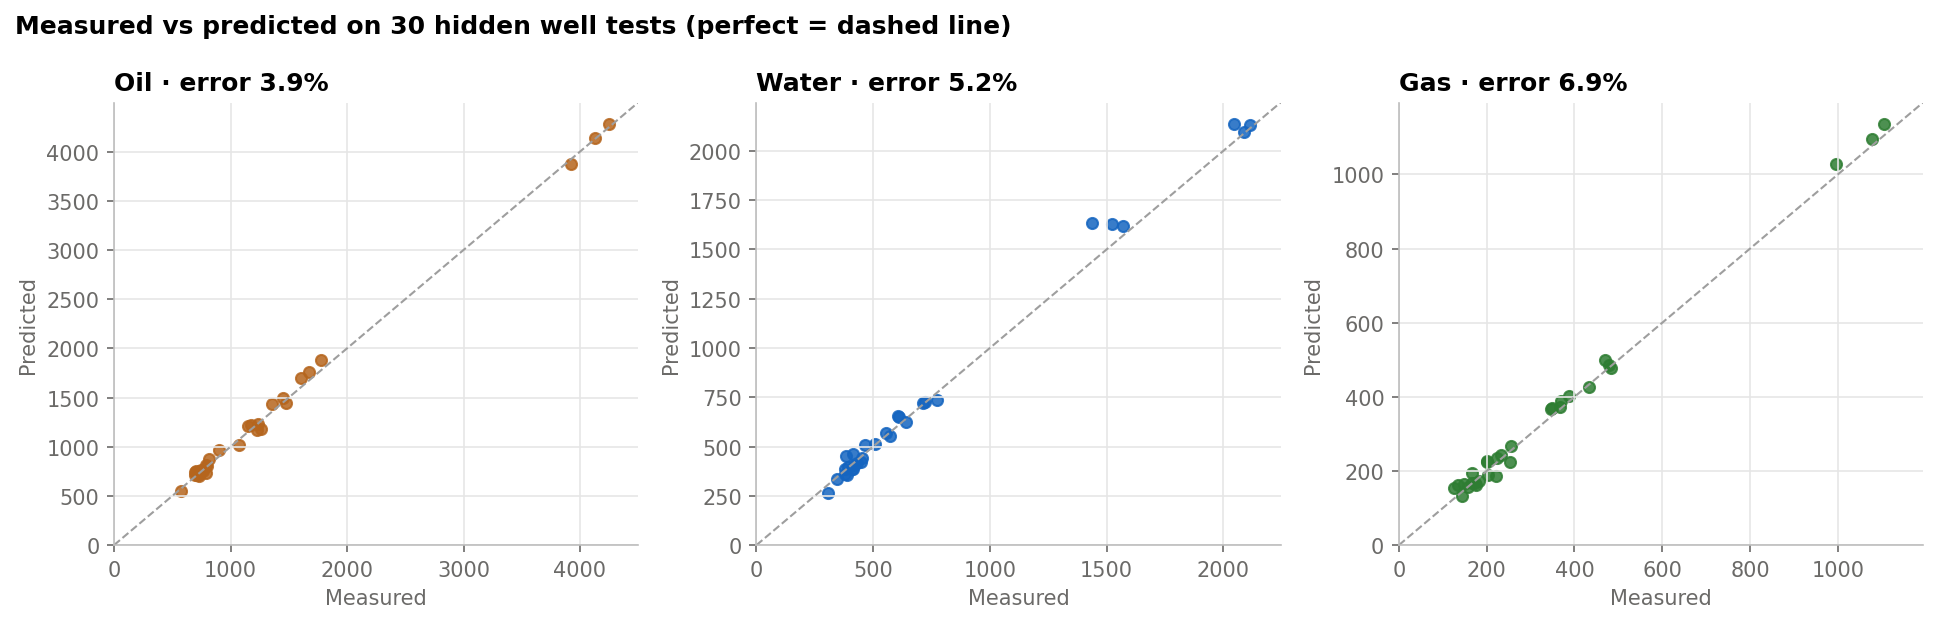

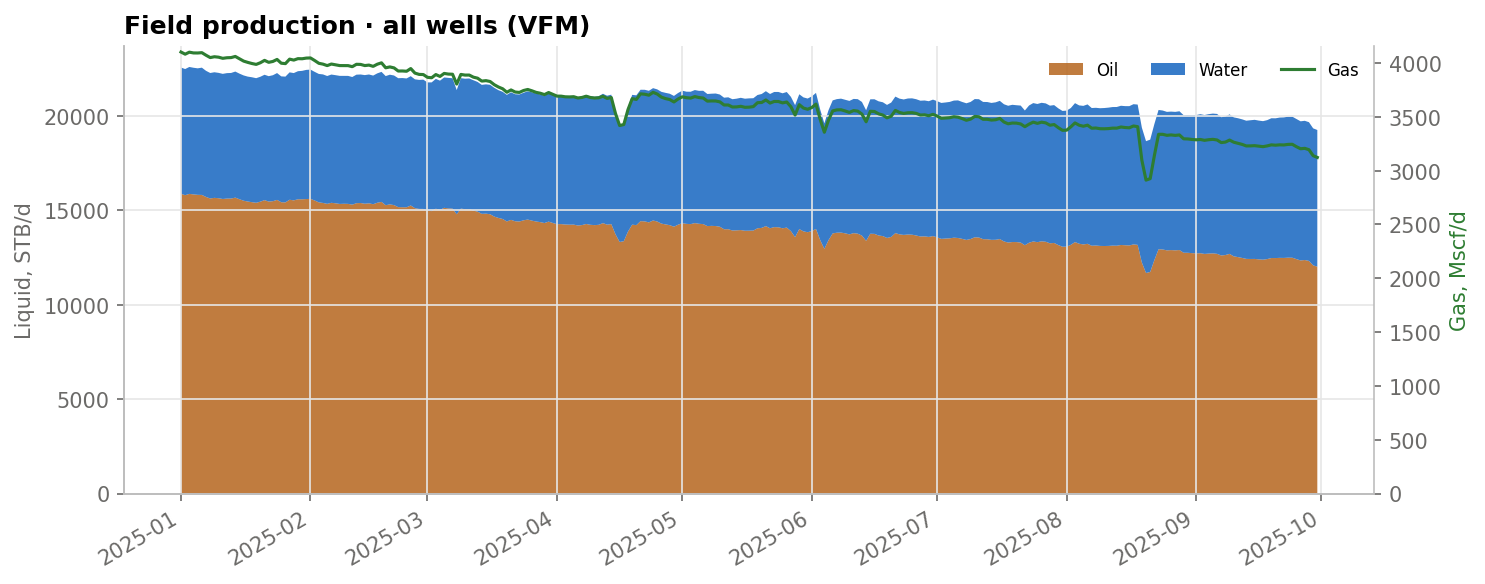

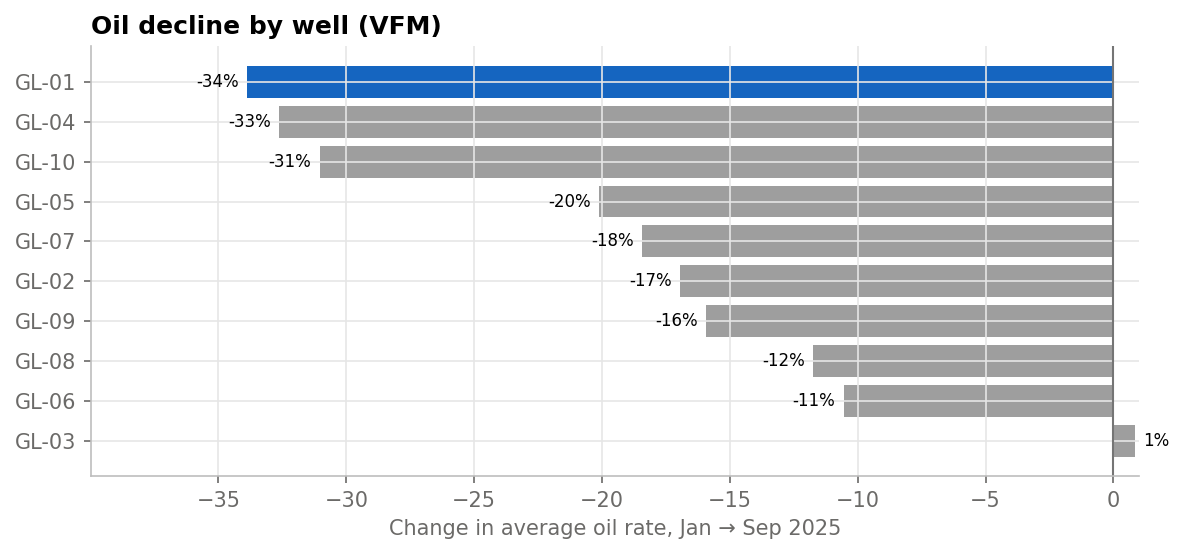

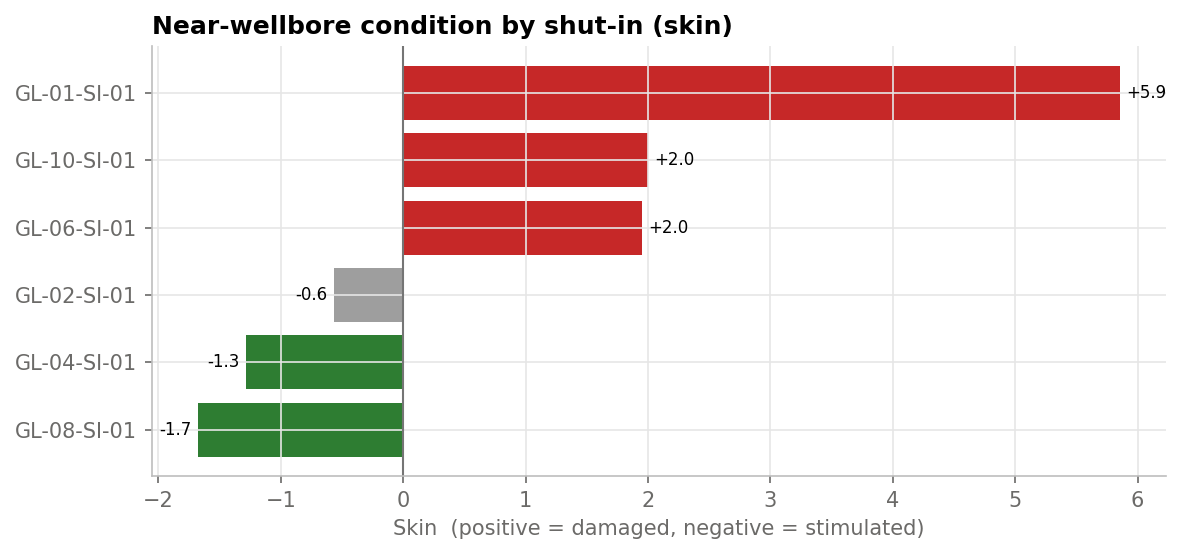

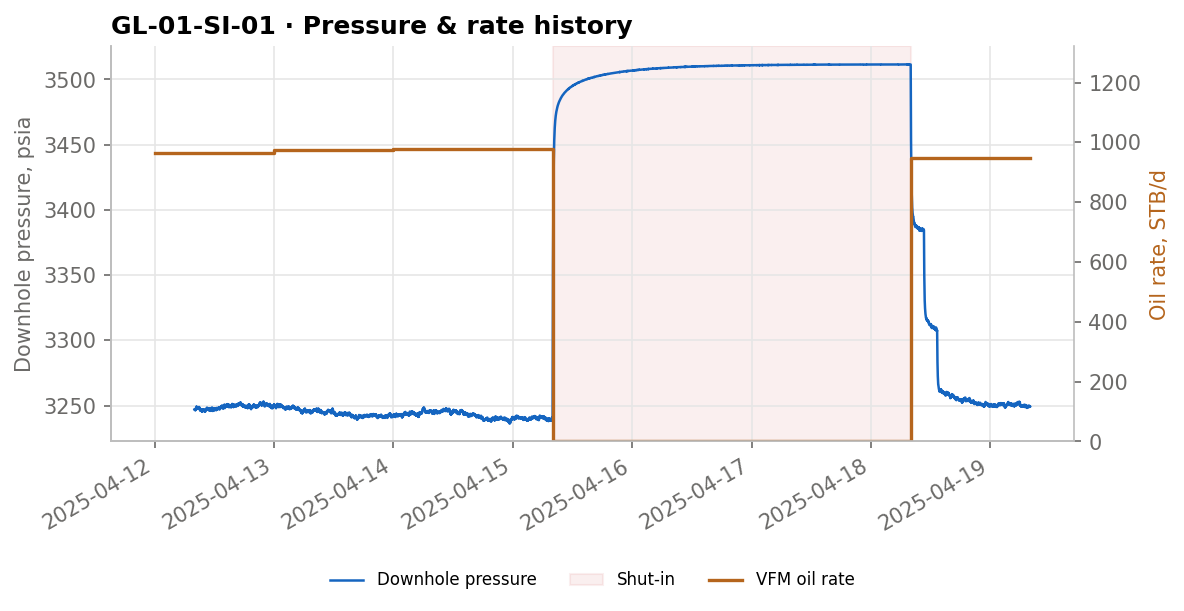

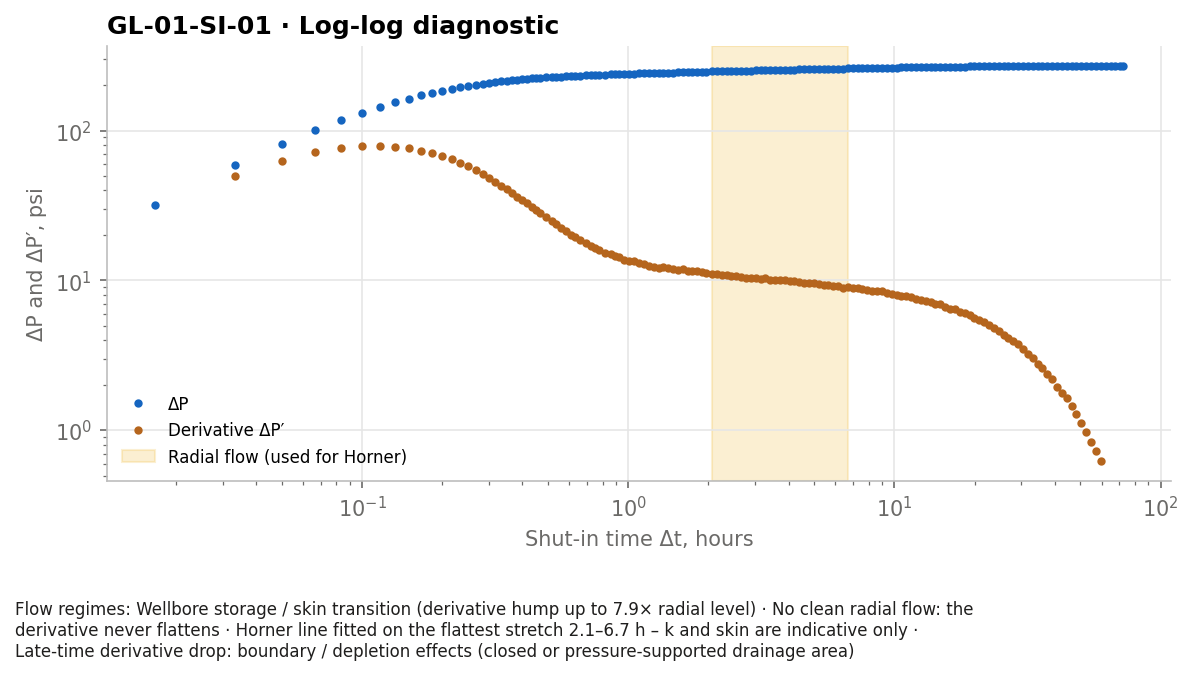

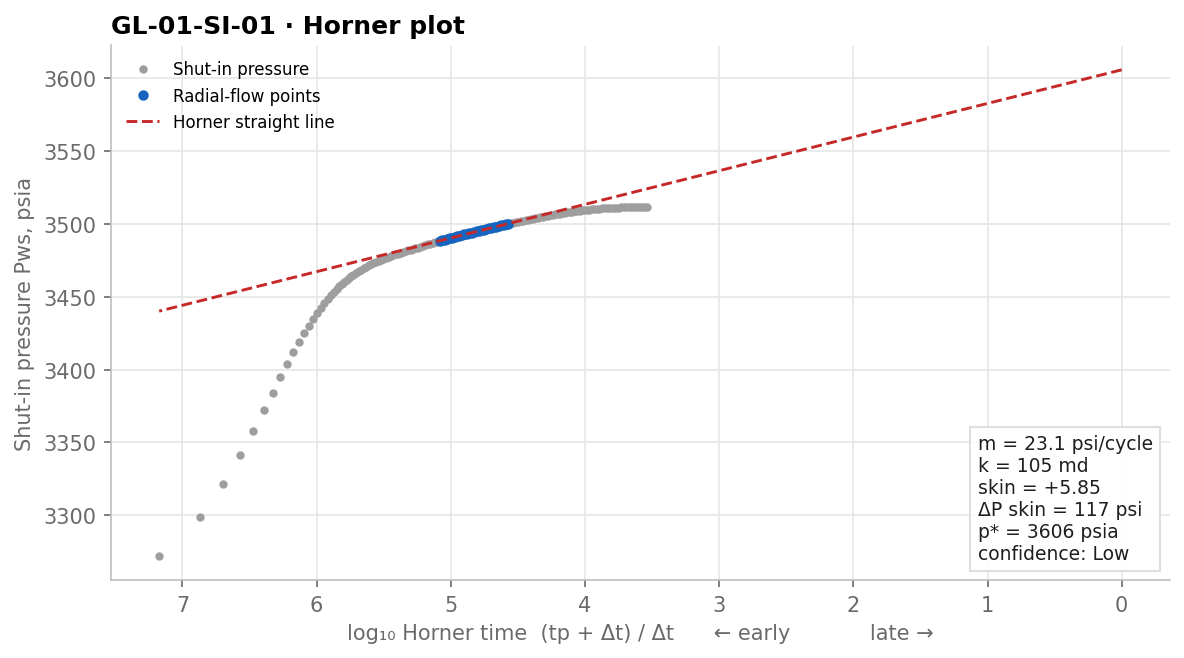

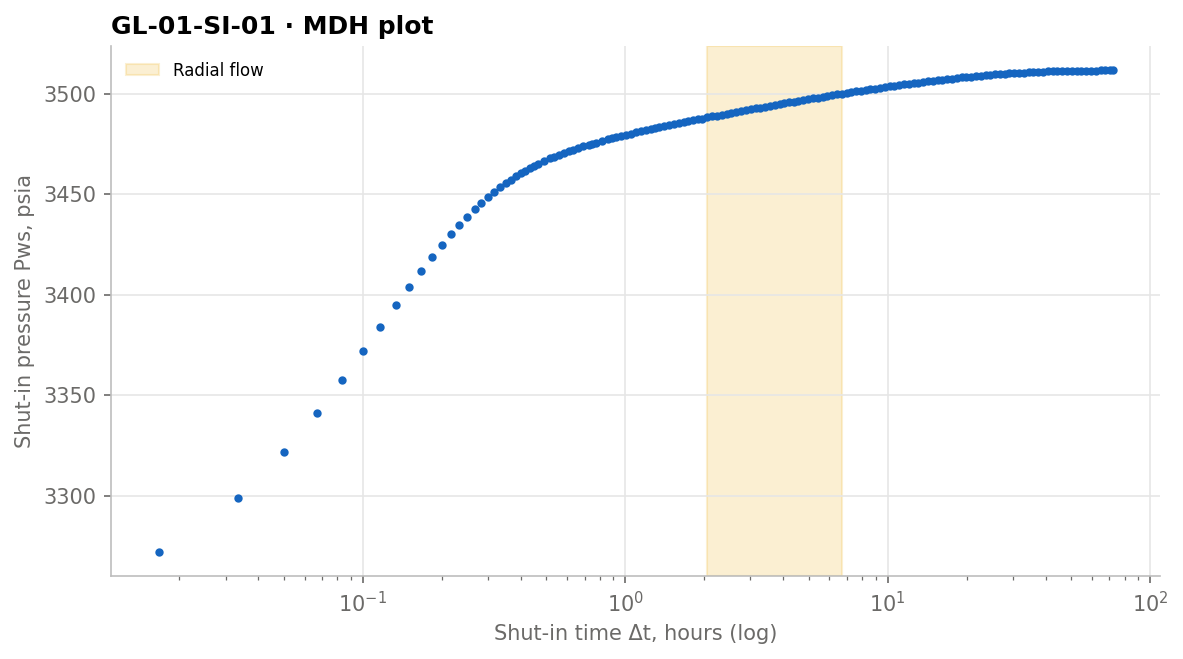

In [45]:
# 9.3 Overview charts (for the app) and one shut-in's PTA plots
for f in ["model_vs_baseline", "measured_vs_predicted", "field_production", "oil_change_by_well", "skin_by_shutin"]:
    display(Image(f"outputs/charts/{f}.png", width=820))
for f in ["1_history", "2_loglog", "3_horner", "4_mdh"]:
    display(Image(f"outputs/pta_plots/GL-01-SI-01_{f}.png", width=700))

In [46]:
# 9.4 Demo-day rehearsal: train on Jan–Jul only, then run on raw Aug–Sep data the model has never seen
cut = pd.Timestamp("2025-08-01")
hf_raw = data.hf; ch_raw = data.choke; wt_raw9 = data.well_tests
train_in = vp.Inputs(hf_raw[hf_raw.timestamp < cut], ch_raw[ch_raw.timestamp < cut], data.completion, data.pvt,
                     wt_raw9[wt_raw9.test_start < cut])
b_janjul, _, _ = vp.train_model(train_in)
last_choke = ch_raw[ch_raw.timestamp < cut].sort_values("timestamp").groupby("well_name").tail(1).assign(timestamp=cut)
test_in = vp.Inputs(hf_raw[hf_raw.timestamp >= cut], pd.concat([last_choke, ch_raw[ch_raw.timestamp >= cut]]),
                    data.completion, data.pvt)
r_test = vp.run_all(test_in, b_janjul)
truth, _ = vp.clean_well_tests(wt_raw9[wt_raw9.test_start >= cut])
m = truth.assign(date=truth.test_start.dt.normalize()).merge(r_test["predictions"], on=["well_name", "date"], suffixes=("", "_p"))
print("Unseen Aug–Sep: error vs measured tests (%) –",
      {t.split("_")[0]: round(float((abs(m[t] - m[t + "_p"]) / m[t]).mean() * 100), 1) for t in vp.TARGETS})
print("Shut-ins found:", list(r_test["events"].event_id))
r_test["pta"][["event_id", "permeability_md", "skin", "condition"]].round(2)

Unseen Aug–Sep: error vs measured tests (%) – {'oil': 3.1, 'water': 4.9, 'gas': 5.8}
Shut-ins found: ['GL-08-SI-01']


,event_id,permeability_md,skin,condition
0,GL-08-SI-01,41.85,-1.67,Stimulated


#### Results – deliverables

- **`models/vfm_model.pkl`** – the trained HybridVFM (J, reservoir-pressure trend, water-cut trend and GOR per well, plus the choke-only model for comparison), with validation scores and cumulative oil for PTA. Loads with `vfm_pipeline.load_model()` (keep the `.py` files in the same folder).
- **`outputs/VFM_predictions.csv` / `.xlsx`** (Phase 1) and **`outputs/PTA_results.csv` / `.xlsx`** (Phase 2) – the CSVs hold the required submission columns; the PTA Excel adds duration, flow regimes, condition and recommendation.
- **`outputs/pta_plots/`** – 24 plots (6 shut-ins × history, log-log, Horner, MDH); **`outputs/charts/`** – field production, oil decline, per-well rates, measured vs predicted, model vs baseline, skin by shut-in.
- **Demo-day rehearsal (9.4):** a model trained only on Jan–Jul predicted raw Aug–Sep files it had never seen with **oil 3.2 %, water 5.2 %, gas 6.2 %** error vs the measured tests, and found the GL-08 shut-in with the same permeability (42.9 vs 43.2 md) and skin (−1.62 vs −1.63). A full run takes about a minute.

## 10. Final version (v2): best results

Sections 1–9 show how we got here. This section runs the **final v2 pipeline** (`vfm_pipeline.py`, trained by `build_model.py`) and shows our best results.

**What v2 adds**
1. **VFM recalibration for new data.** When new well tests are uploaded, reservoir pressure, water cut and GOR are refitted with recency weighting (90-day half-life), using only tests that had already ended. J stays fixed.
2. **Robust PTA.** The radial-flow window is the longest stretch with a flat derivative (±5 %), each event gets a confidence level, and the flow regimes are read from the data.
3. **Robustness for demo-day uploads.** Choke setting carried over at the start of the period, early shut-ins handled, failed events reported instead of crashing.

In [47]:
# 10.1 Load the final models (.pkl)
import pickle, pandas as pd, vfm_pipeline as vp
from IPython.display import Image, display
bundle = vp.load_model("models/vfm_model.pkl")
pta_pkl = pickle.load(open("models/pta_results.pkl", "rb"))
print(f"VFM: {type(bundle.model).__name__} v{bundle.version} | trained on {bundle.trained_on} | {bundle.n_tests} tests | half-life {bundle.half_life_days} d")
print(f"PTA: {pta_pkl['method']} | {len(pta_pkl['results'])} shut-ins")
pd.DataFrame({"J_stbd_per_psi": bundle.model.J}).round(2).T

VFM: HybridVFM v2.0 | trained on 2025-01-01 – 2025-09-30 | 85 tests | half-life 90 d
PTA: Horner / Bourdet build-up analysis, single-phase oil, VFM oil rate | 6 shut-ins


,GL-01,GL-02,GL-03,GL-04,GL-05,GL-06,GL-07,GL-08,GL-09,GL-10
J_stbd_per_psi,6.55,9.91,1.4,1.51,1.13,8.37,23.08,4.56,3.47,12.04


### 10.2 VFM validation: three independent checks

In [48]:
v = bundle.validation
loo = pd.DataFrame(v["leave_one_out"]).set_index("rate").round(3)
print("Leave-one-test-out (85 tests):"); display(loo)
reh = pd.DataFrame(v["rehearsal_train_jan_jun_upload_jul_sep"])
print("DEMO-DAY REHEARSAL: train Jan–Jun, upload Jul–Sep (28 unseen tests), MAPE %:")
display(reh.pivot(index="rate", columns="who", values="MAPE_%").round(2)[["v2_recalibrated", "v1_frozen", "baseline_last_test"]])
print("R² and WAPE % on the rehearsal:")
display(reh.pivot(index="rate", columns="who", values="R2").round(3)[["v2_recalibrated", "v1_frozen", "baseline_last_test"]])
display(reh.pivot(index="rate", columns="who", values="WAPE_%").round(2)[["v2_recalibrated", "v1_frozen", "baseline_last_test"]])

Leave-one-test-out (85 tests):


,R2,MAPE_%,WAPE_%,RMSE
rate,,,,
oil_rate_stbd,0.999,2.667,2.203,41.260
water_rate_stbd,0.995,4.273,3.715,36.589
gas_rate_mscfd,0.995,5.927,4.454,20.888


DEMO-DAY REHEARSAL: train Jan–Jun, upload Jul–Sep (28 unseen tests), MAPE %:


who,v2_recalibrated,v1_frozen,baseline_last_test
rate,,,
gas_rate_mscfd,6.45,7.80,11.80
oil_rate_stbd,3.26,4.44,6.73
water_rate_stbd,4.19,5.47,5.25


R² and WAPE % on the rehearsal:


who,v2_recalibrated,v1_frozen,baseline_last_test
rate,,,
gas_rate_mscfd,0.995,0.992,0.984
oil_rate_stbd,0.997,0.995,0.988
water_rate_stbd,0.993,0.983,0.993


who,v2_recalibrated,v1_frozen,baseline_last_test
rate,,,
gas_rate_mscfd,4.79,6.10,8.49
oil_rate_stbd,2.72,3.83,6.00
water_rate_stbd,4.04,6.09,4.79


**Reading the rehearsal:** this copies the jury's test (new months, new files only). v2 cuts the oil error from 4.4 % to **3.3 %** (water 5.5 → 4.2 %, gas 7.8 → 6.4 %), and it beats simply reusing the last well test (6.7 % / 5.2 % / 11.8 %). Leave-one-out is slightly optimistic (J was estimated with all tests), so the rehearsal is our honest number.

### 10.3 Phase 1 deliverable: daily VFM predictions (10 wells × 273 days)

(2730, 5) | columns: ['date', 'well_name', 'oil_rate_stbd', 'water_rate_stbd', 'gas_rate_mscfd']


,avg_oil_rate_stbd,avg_water_rate_stbd,avg_gas_rate_mscfd
well_name,,,
GL-01,936.5,731.1,258.0
GL-02,1209.0,1422.7,364.8
GL-03,730.5,370.0,161.9
GL-04,738.4,337.3,178.2
GL-05,765.4,408.9,242.9
GL-06,718.8,498.3,153.0
GL-07,4362.9,1900.9,1154.9
GL-08,1425.6,377.9,476.6
GL-09,1254.8,353.9,202.1


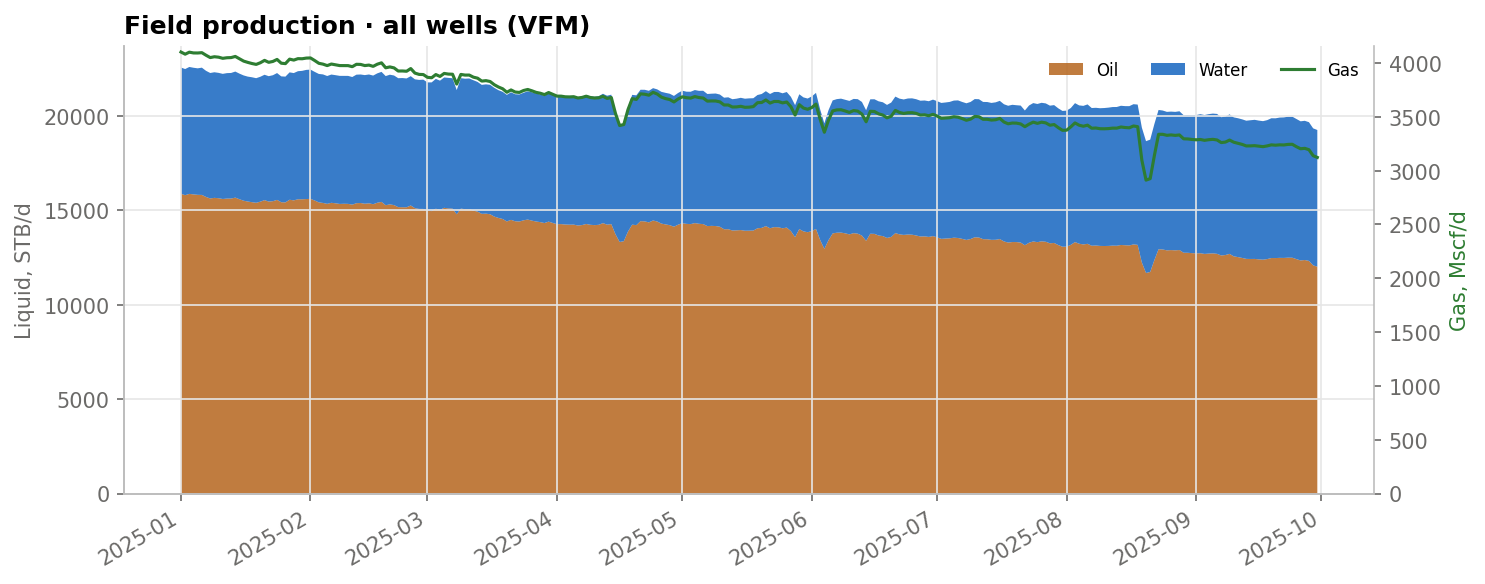

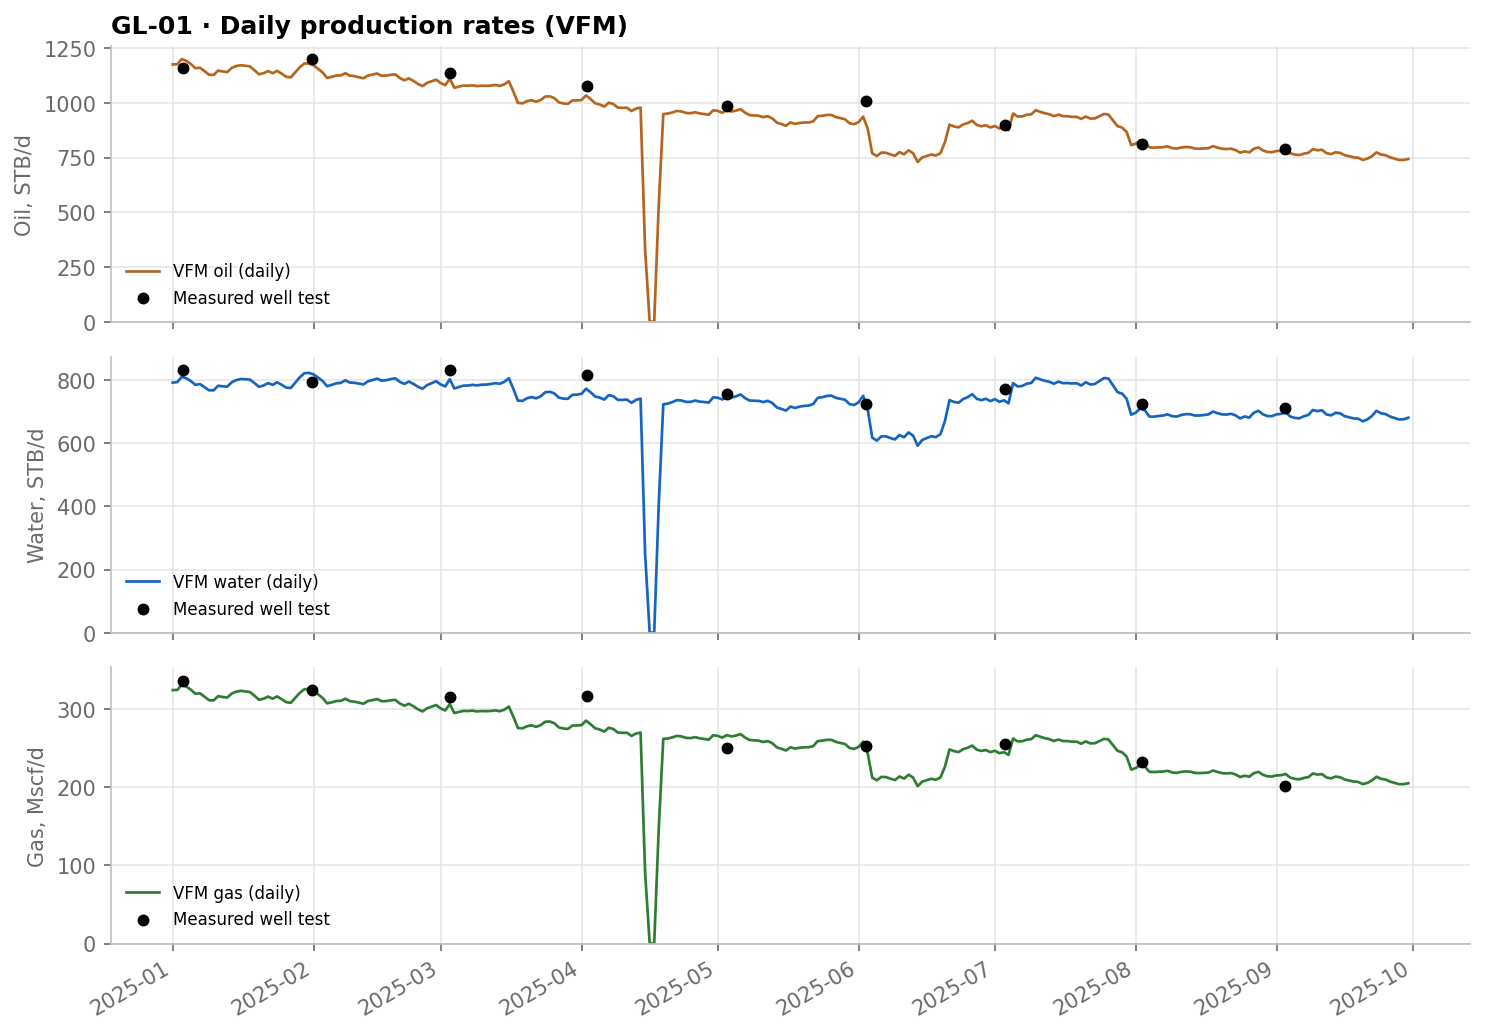

In [49]:
pred = pd.read_csv("outputs/VFM_predictions.csv", parse_dates=["date"])
print(pred.shape, "| columns:", list(pred.columns))
display(pred.groupby("well_name")[vp.TARGETS].mean().round(1).rename(columns=lambda c: "avg_" + c))
display(Image("outputs/charts/field_production.png", width=820))
display(Image("outputs/charts/rates_GL-01.png", width=820))

### 10.4 Phase 2 deliverable: PTA results for every shut-in (v2)

In [50]:
pta = pta_pkl["results"]
display(pta[["event_id", "t_shut", "duration_hr", "q_oil_stbd", "horner_slope_psi_per_cycle", "permeability_md", "skin",
             "delta_p_skin_psi", "flow_efficiency", "fit_from_hr", "fit_to_hr", "confidence", "condition"]].round(2))
for r in pta.itertuples():
    print(f"{r.event_id}: {r.summary}")

,event_id,t_shut,duration_hr,q_oil_stbd,horner_slope_psi_per_cycle,permeability_md,skin,delta_p_skin_psi,flow_efficiency,fit_from_hr,fit_to_hr,confidence,condition
0,GL-01-SI-01,2025-04-15 08:00:00,72.00,971.98,23.08,104.67,5.85,117.41,0.68,2.06,6.68,Low,Damaged
1,GL-02-SI-01,2025-03-08 14:23:00,5.65,1267.49,53.18,55.33,-0.57,-26.16,1.05,1.25,4.81,Medium,Undamaged
2,GL-04-SI-01,2025-06-03 08:00:00,48.00,802.15,146.01,54.70,-1.29,-163.35,1.12,11.59,40.09,Medium,Stimulated
3,GL-06-SI-01,2025-07-22 03:11:00,8.00,686.30,15.04,298.63,1.95,25.49,0.86,1.89,6.75,Medium,Slightly damaged
4,GL-08-SI-01,2025-08-19 09:00:00,72.00,1467.10,93.73,42.79,-1.68,-136.58,1.17,1.60,59.59,High,Stimulated
5,GL-10-SI-01,2025-05-27 21:04:00,9.00,1723.50,28.94,171.69,2.00,50.37,0.86,0.91,2.93,Low,Slightly damaged


GL-01-SI-01: Damaged well (skin +5.9, flow efficiency 68%) in moderate-permeability rock (105 md). Confidence: Low. Stimulation candidate: removing skin could raise rate up to ~47% at the same drawdown (confirm with a longer build-up: radial flow not clearly reached).
GL-02-SI-01: Undamaged well (skin -0.6, flow efficiency 105%) in moderate-permeability rock (55 md). Confidence: Medium. No near-wellbore action needed.
GL-04-SI-01: Stimulated well (skin -1.3, flow efficiency 112%) in moderate-permeability rock (55 md). Confidence: Medium. Near-wellbore zone flows better than the rock; no action needed.
GL-06-SI-01: Slightly damaged well (skin +2.0, flow efficiency 86%) in high-permeability rock (299 md). Confidence: Medium. Monitor; consider stimulation if rate declines faster than neighbours.
GL-08-SI-01: Stimulated well (skin -1.7, flow efficiency 117%) in low-permeability rock (43 md). Confidence: High. Near-wellbore zone flows better than the rock; no action needed.
GL-10-SI-01: Sli

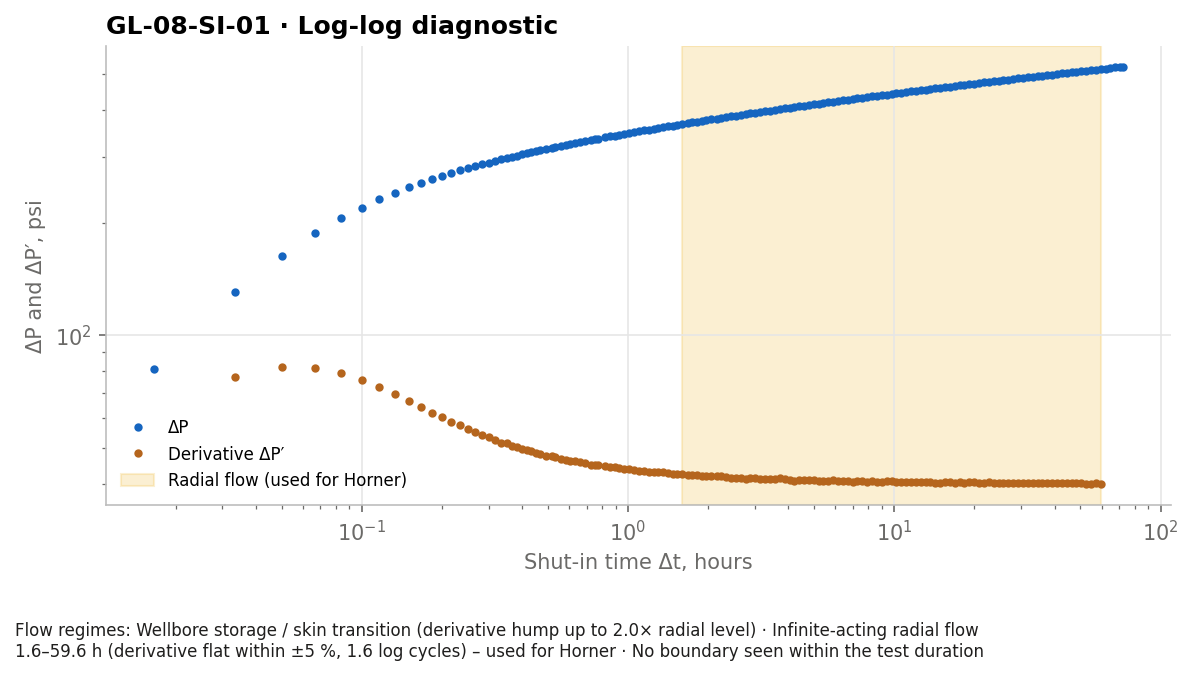

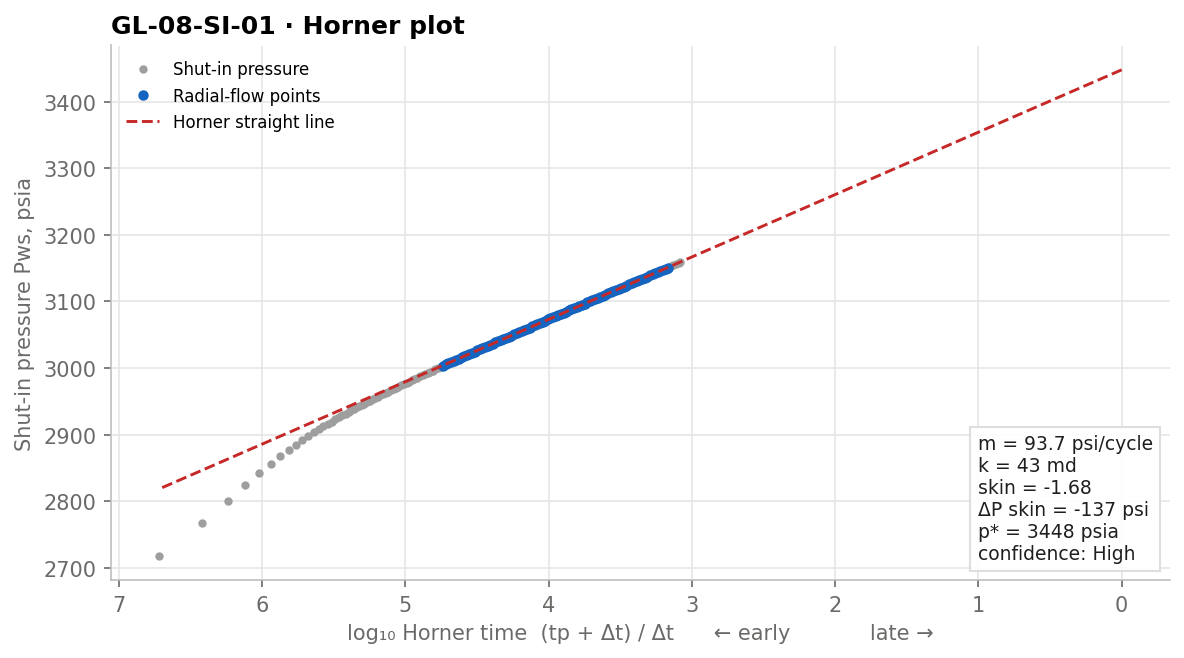

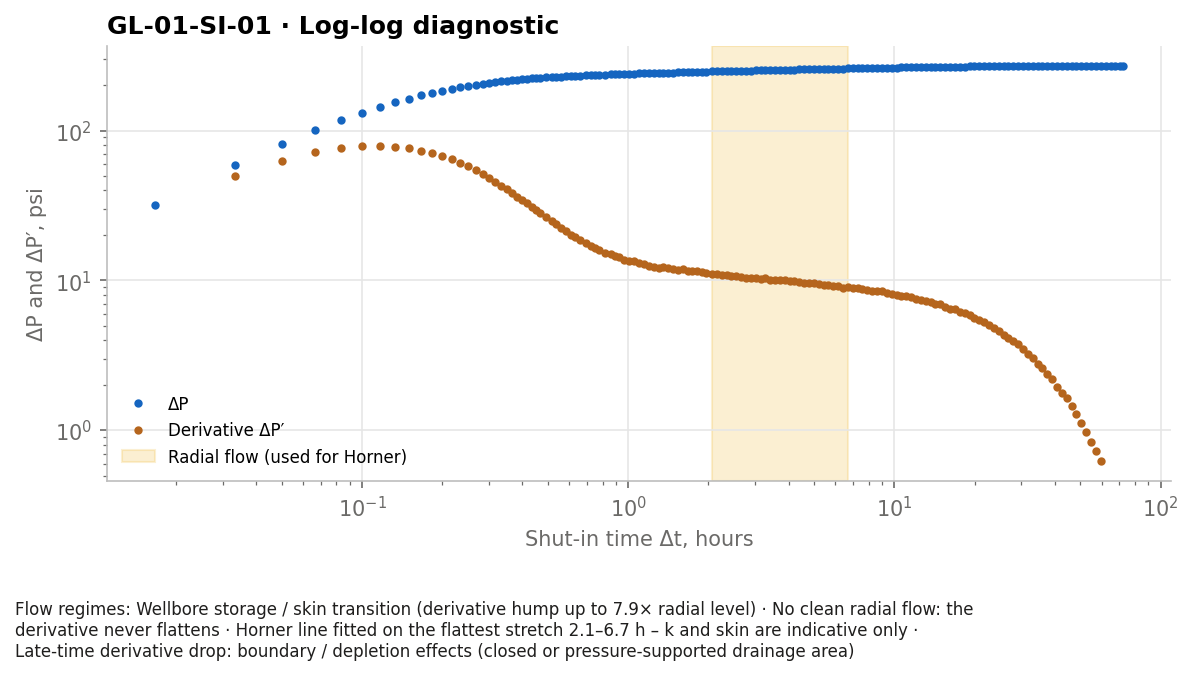

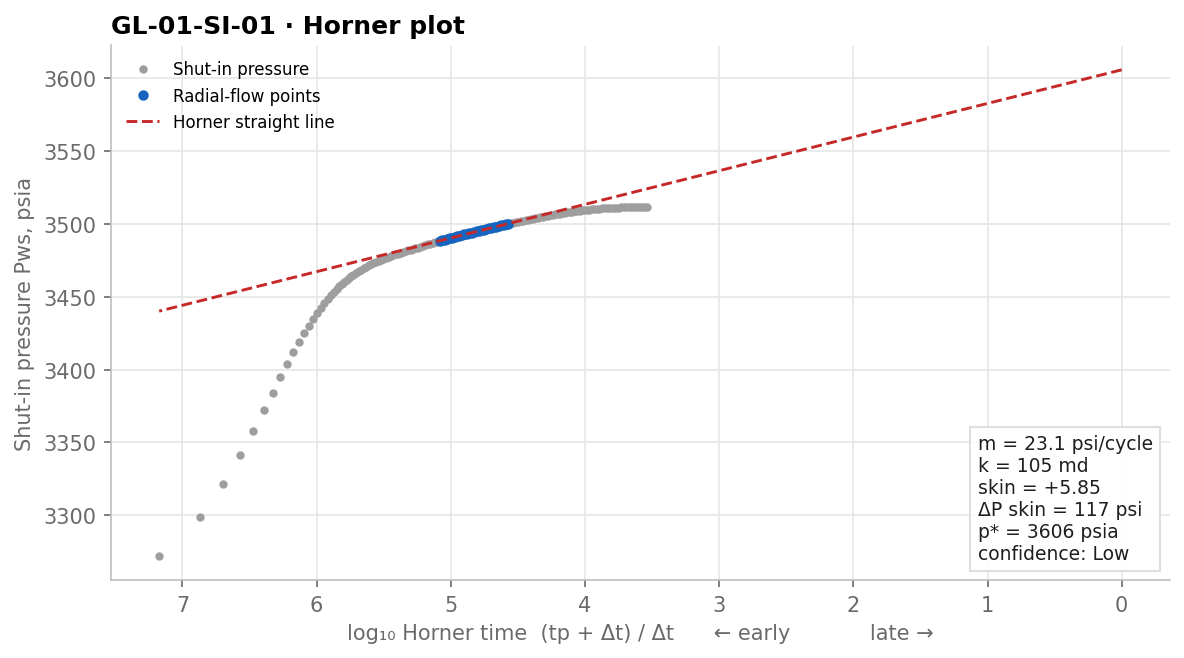

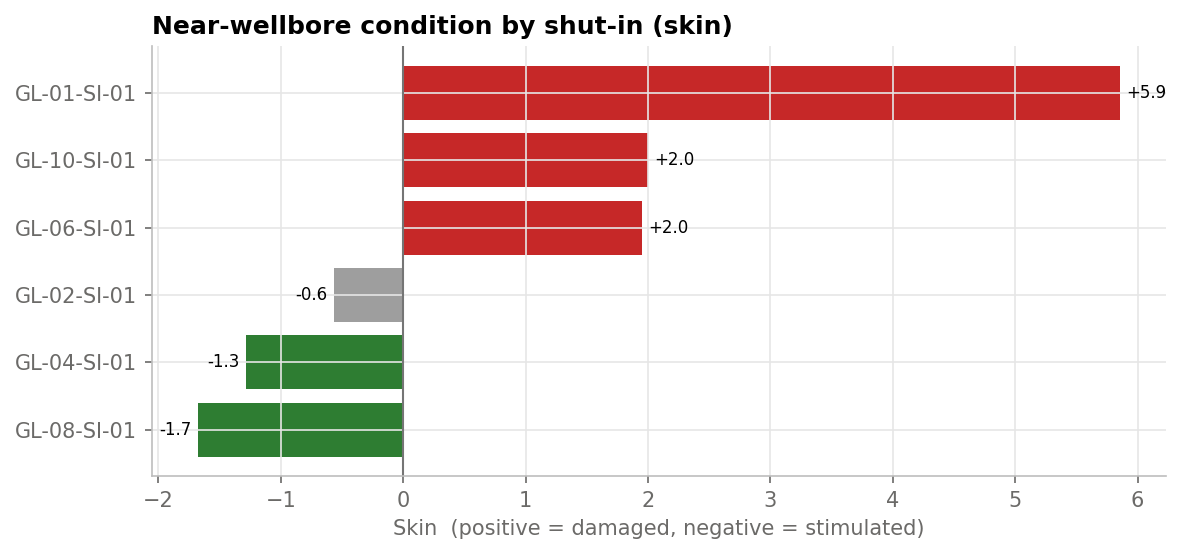

In [51]:
# PTA plots (all 24 are in outputs/pta_plots/): best-quality event GL-08 and the damaged well GL-01
for f in ["GL-08-SI-01_2_loglog", "GL-08-SI-01_3_horner", "GL-01-SI-01_2_loglog", "GL-01-SI-01_3_horner"]:
    display(Image(f"outputs/pta_plots/{f}.png", width=760))
display(Image("outputs/charts/skin_by_shutin.png", width=700))

### 10.5 Final results summary

| | Result |
|---|---|
| **VFM accuracy, 3 unseen months** | Oil **3.3 %**, water **4.2 %**, gas **6.4 %** MAPE (baseline: 6.7 / 5.2 / 11.8 %) |
| **VFM accuracy, leave-one-out** | Oil 2.7 %, water 4.3 %, gas 5.9 % MAPE, R² ≥ 0.995 |
| **PTA** | 6 build-ups, 4 plots each. GL-01 damaged (skin ≈ +5.9, FE ≈ 68 %): stimulation candidate. GL-04 and GL-08 stimulated. GL-08 highest-confidence result (radial flow over 1.6 log cycles) |
| **Deliverables** | `outputs/VFM_predictions.csv/.xlsx`, `outputs/PTA_results.csv/.xlsx`, `models/vfm_model.pkl`, `models/pta_results.pkl`, `outputs/pta_plots/` (24 plots) |

Reproduce everything: `python build_model.py`